In [35]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import re
import json
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [36]:
import requests

url ="https://www.carwale.com/hyundai-cars/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print("Status Code:", response.status_code)
print("Response Length:", len(response.text))

Status Code: 200
Response Length: 603660


In [37]:
soup = BeautifulSoup(response.text, "html.parser")

In [58]:
car_names = soup.find_all("h3")

print("Number of H3 elements:", len(car_names))

for name in car_names[:10]:
    print(name.get_text(" ", strip=True))

Number of H3 elements: 27
Hyundai Creta
Hyundai Venue
Hyundai i20
Hyundai Exter
Hyundai Grand i10 Nios
Hyundai Verna
Hyundai Aura
Hyundai Alcazar
Hyundai Creta Electric
Hyundai Venue N Line


In [59]:
links = soup.find_all("a")

print("Total links:", len(links))

Total links: 210


# Find Hyundai Car URLs

In [60]:
car_links = []

for link in links:

    href = link.get("href")
    name = link.get_text(" ", strip=True)

    if href and "/hyundai-cars/" in href:

        if name:
            car_links.append({
                "Car Name": name,
                "URL": href
            })

In [61]:
car_links

[{'Car Name': 'Hyundai Creta', 'URL': '/hyundai-cars/creta/'},
 {'Car Name': 'Offers', 'URL': '/hyundai-cars/creta/?showOfferUpfront=true'},
 {'Car Name': 'Check On Road Price',
  'URL': '/hyundai-cars/creta/price-in-mumbai/'},
 {'Car Name': 'Hyundai Venue', 'URL': '/hyundai-cars/venue/'},
 {'Car Name': 'Check On Road Price',
  'URL': '/hyundai-cars/venue/price-in-mumbai/'},
 {'Car Name': 'Hyundai i20', 'URL': '/hyundai-cars/i20/'},
 {'Car Name': 'Offers', 'URL': '/hyundai-cars/i20/?showOfferUpfront=true'},
 {'Car Name': 'Check On Road Price',
  'URL': '/hyundai-cars/i20/price-in-mumbai/'},
 {'Car Name': 'Hyundai Exter', 'URL': '/hyundai-cars/exter/'},
 {'Car Name': 'Offers', 'URL': '/hyundai-cars/exter/?showOfferUpfront=true'},
 {'Car Name': 'Check On Road Price',
  'URL': '/hyundai-cars/exter/price-in-mumbai/'},
 {'Car Name': 'Hyundai Grand i10 Nios',
  'URL': '/hyundai-cars/grand-i10-nios/'},
 {'Car Name': 'Offers',
  'URL': '/hyundai-cars/grand-i10-nios/?showOfferUpfront=true'},
 {

## Convert to DataFrame

In [62]:
car_links_df = pd.DataFrame(car_links)

In [63]:
car_links_df

,Car Name,URL
0,Hyundai Creta,/hyundai-cars/creta/
1,Offers,/hyundai-cars/creta/?showOfferUpfront=true
2,Check On Road Price,/hyundai-cars/creta/price-in-mumbai/
3,Hyundai Venue,/hyundai-cars/venue/
4,Check On Road Price,/hyundai-cars/venue/price-in-mumbai/
...,...,...
106,Alcazar [2023-2024],/hyundai-cars/alcazar-2023-2024/
107,i20 N Line [2021-2023],/hyundai-cars/i20-n-line-2021-2023/
108,Casper,/hyundai-cars/casper/
109,Genesis,/hyundai-cars/genesis/


In [64]:
car_links_df.head()

,Car Name,URL
0,Hyundai Creta,/hyundai-cars/creta/
1,Offers,/hyundai-cars/creta/?showOfferUpfront=true
2,Check On Road Price,/hyundai-cars/creta/price-in-mumbai/
3,Hyundai Venue,/hyundai-cars/venue/
4,Check On Road Price,/hyundai-cars/venue/price-in-mumbai/


## Remove Duplicate URLs

In [65]:
car_links_df = car_links_df.drop_duplicates(
    subset="URL"
)

In [66]:
car_links_df

,Car Name,URL
0,Hyundai Creta,/hyundai-cars/creta/
1,Offers,/hyundai-cars/creta/?showOfferUpfront=true
2,Check On Road Price,/hyundai-cars/creta/price-in-mumbai/
3,Hyundai Venue,/hyundai-cars/venue/
4,Check On Road Price,/hyundai-cars/venue/price-in-mumbai/
...,...,...
106,Alcazar [2023-2024],/hyundai-cars/alcazar-2023-2024/
107,i20 N Line [2021-2023],/hyundai-cars/i20-n-line-2021-2023/
108,Casper,/hyundai-cars/casper/
109,Genesis,/hyundai-cars/genesis/


In [67]:
def make_full_url(url):

    if url.startswith("http"):
        return url

    return "https://www.carwale.com" + url

In [68]:
import warnings
warnings.filterwarnings('ignore')
car_links_df["URL"] = car_links_df["URL"].apply(
    make_full_url
)

In [69]:
car_links_df["URL"]

0            https://www.carwale.com/hyundai-cars/creta/
1      https://www.carwale.com/hyundai-cars/creta/?sh...
2      https://www.carwale.com/hyundai-cars/creta/pri...
3            https://www.carwale.com/hyundai-cars/venue/
4      https://www.carwale.com/hyundai-cars/venue/pri...
                             ...                        
106    https://www.carwale.com/hyundai-cars/alcazar-2...
107    https://www.carwale.com/hyundai-cars/i20-n-lin...
108         https://www.carwale.com/hyundai-cars/casper/
109        https://www.carwale.com/hyundai-cars/genesis/
110             https://www.carwale.com/hi/hyundai-cars/
Name: URL, Length: 96, dtype: object

## Check the Car Names

In [70]:
for i, row in car_links_df.iterrows():

    print(
        i + 1,
        row["Car Name"],
        "->",
        row["URL"]
    )

1 Hyundai Creta -> https://www.carwale.com/hyundai-cars/creta/
2 Offers -> https://www.carwale.com/hyundai-cars/creta/?showOfferUpfront=true
3 Check On Road Price -> https://www.carwale.com/hyundai-cars/creta/price-in-mumbai/
4 Hyundai Venue -> https://www.carwale.com/hyundai-cars/venue/
5 Check On Road Price -> https://www.carwale.com/hyundai-cars/venue/price-in-mumbai/
6 Hyundai i20 -> https://www.carwale.com/hyundai-cars/i20/
7 Offers -> https://www.carwale.com/hyundai-cars/i20/?showOfferUpfront=true
8 Check On Road Price -> https://www.carwale.com/hyundai-cars/i20/price-in-mumbai/
9 Hyundai Exter -> https://www.carwale.com/hyundai-cars/exter/
10 Offers -> https://www.carwale.com/hyundai-cars/exter/?showOfferUpfront=true
11 Check On Road Price -> https://www.carwale.com/hyundai-cars/exter/price-in-mumbai/
12 Hyundai Grand i10 Nios -> https://www.carwale.com/hyundai-cars/grand-i10-nios/
13 Offers -> https://www.carwale.com/hyundai-cars/grand-i10-nios/?showOfferUpfront=true
14 Check O

In [71]:
print("Total car URLs:", len(car_links_df))

Total car URLs: 96


In [72]:
car_name = soup.find_all("h3")

print("Number of H3 elements:", len(car_names))

for name in car_names[:10]:
    print(name.get_text(" ", strip=True))

Number of H3 elements: 27
Hyundai Creta
Hyundai Venue
Hyundai i20
Hyundai Exter
Hyundai Grand i10 Nios
Hyundai Verna
Hyundai Aura
Hyundai Alcazar
Hyundai Creta Electric
Hyundai Venue N Line


## SCRAPE THE 9 REQUIRED COLUMNS

## Testing ONE Car First

In [73]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

In [74]:
test_url

'https://www.carwale.com/hyundai-cars/creta/'

In [75]:
response = requests.get(test_url)

print(response.status_code)

200


In [76]:
test_soup = BeautifulSoup(
    response.text,
    "html.parser"
)

In [77]:
test_soup


<!DOCTYPE html>
<html itemscope="" itemtype="http://schema.org/WebPage" lang="en" prefix="og: http://ogp.me/ns# fb: http://ogp.me/ns/fb#"><head><meta charset="utf-8"/><meta content="#0e3a50" name="theme-color"/><meta content="max-snippet:-1, max-image-preview:large" name="robots">
<title data-react-helmet="true" itemprop="name">Hyundai Creta Price - Images, Colours &amp; Reviews - CarWale</title>
<link crossorigin="" href="https://imgd.aeplcdn.com" rel="preconnect dns-prefetch"/><link crossorigin="" href="https://stc.aeplcdn.com" rel="preconnect dns-prefetch"/><link crossorigin="" href="https://www.googletagmanager.com" rel="dns-prefetch"/><link crossorigin="" href="https://www.googletagservices.com" rel="dns-prefetch"/><link crossorigin="" href="https://bid.g.doubleclick.net" rel="dns-prefetch"/><link crossorigin="" href="https://pagead2.googlesyndication.com" rel="dns-prefetch"/><link crossorigin="" href="https://googleads.g.doubleclick.net" rel="dns-prefetch"/><link crossorigin="" 

## Get Creta Page Text

In [78]:
text = test_soup.get_text(
    " ",
    strip=True
)

print(text[:10000])

Hyundai Creta Price - Images, Colours & Reviews - CarWale NEW CARS USED CARS REVIEWS & NEWS AD Hyundai Creta 4.1 Expert Rating | 4.6 User Rating (711) Rate & Win The Hyundai Creta has premium looks, consistent quality, and a spacious and feature-rich cabin (including blind-spot monitoring, 360-degree camera, and panoramic sunroof). Both of its engine options, the 1.5-litre petrol or diesel, drive well and get smooth automatic and manual gearboxes. Hyundai Creta price starts from Rs. 10.91 Lakh for base model and goes upto Rs. 20.46 Lakh (ex-showroom) for top model as of September 2026. Hyundai Creta Price Details: Base Variant (E) : Rs. 10.91 Lakh - Rs. 12.53 Lakh Top Variant (King Lounge Edition) : Rs. 19.22 Lakh - Rs. 20.46 Lakh Automatic Variant Price : Rs. 14.5 Lakh - Rs. 20.46 Lakh On-Road Price, Mumbai : Rs. 13.08 Lakh - Rs. 24.81 Lakh Hyundai Creta Engine & Variant Options: Engine Options : 2WD Petrol 1497cc, 2WD Diesel 1493cc Turbo and 2WD Petrol 1482cc Turbo Transmission : Man

## Find User Rating

In [79]:
rating_match = re.search(
    r"User Rating\s*\(?(\d+\.?\d*)",
    text,
    re.IGNORECASE
)

if rating_match:
    rating = rating_match.group(1)
else:
    rating = np.nan

print(rating)

711


## Find Price

In [80]:
price_match = re.search(
    r"(?:Rs\.?|₹)\s*([\d.]+)\s*Lakh",
    text,
    re.IGNORECASE
)

if price_match:
    price = price_match.group(1)
else:
    price = np.nan

print(price)

10.91


## Create Scraping Function

In [81]:
def scrape_car(car_name, car_url):

    print("Scraping:", car_name)

    try:

        response = requests.get(
            car_url,
            timeout=20
        )

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        text = soup.get_text(
            " ",
            strip=True
        )

        # -------------------------
        # PRICE
        # -------------------------

        price_match = re.search(
            r"(?:Rs\.?|₹)\s*([\d.]+)\s*Lakh",
            text,
            re.IGNORECASE
        )

        if price_match:
            price = price_match.group(1)
        else:
            price = np.nan


        # -------------------------
        # USER RATING
        # -------------------------

        rating_match = re.search(
            r"User Rating\s*\(?(\d+\.?\d*)",
            text,
            re.IGNORECASE
        )

        if rating_match:
            rating = rating_match.group(1)
        else:
            rating = np.nan


        # -------------------------
        # RETURN DATA
        # -------------------------

        return {
            "Car Name": car_name,
            "Brand": "Hyundai",
            "Price": price,
            "Fuel Type": np.nan,
            "Transmission": np.nan,
            "Engine": np.nan,
            "Mileage": np.nan,
            "Seating Capacity": np.nan,
            "User Rating": rating
        }

    except Exception as e:

        print(
            "Error:",
            car_name,
            e
        )

        return None

## EXTRACT SPECIFICATIONS

In [82]:
for tag in test_soup.find_all(
    ["div", "li", "span", "p"]
):

    text = tag.get_text(
        " ",
        strip=True
    )

    if any(word in text.lower()
           for word in [
               "engine",
               "fuel type",
               "transmission",
               "mileage",
               "seating capacity"
           ]):

        if len(text) < 500:

            print(text)

The Hyundai Creta has premium looks, consistent quality, and a spacious and feature-rich cabin (including blind-spot monitoring, 360-degree camera, and panoramic sunroof). Both of its engine options, the 1.5-litre petrol or diesel, drive well and get smooth automatic and manual gearboxes.
The Hyundai Creta has premium looks, consistent quality, and a spacious and feature-rich cabin (including blind-spot monitoring, 360-degree camera, and panoramic sunroof). Both of its engine options, the 1.5-litre petrol or diesel, drive well and get smooth automatic and manual gearboxes.
Hyundai Creta Engine & Variant Options: Engine Options : 2WD Petrol 1497cc, 2WD Diesel 1493cc Turbo and 2WD Petrol 1482cc Turbo Transmission : Manual, Automatic (CVT), Automatic (TC) and Automatic (DCT) Variants : Available in 38 variants primarily in E, EX, EX (O) and S (O)
Hyundai Creta Engine & Variant Options:
Engine Options : 2WD Petrol 1497cc, 2WD Diesel 1493cc Turbo and 2WD Petrol 1482cc Turbo Transmission : M

In [83]:
car_name = soup.find("h1").get_text(strip=True)
print(car_name)

Hyundai Cars


In [84]:
price = ""
fuel_type = ""
transmission = ""
engine = ""
mileage = ""
seating_capacity = ""
rating = ""

In [85]:
car = {
    "Car Name": car_name,
    "Brand": "Hyundai",
    "Price": price,
    "Fuel Type": fuel_type,
    "Transmission": transmission,
    "Engine": engine,
    "Mileage": mileage,
    "Seating Capacity": seating_capacity,
    "User Rating": rating
}

print(car)

{'Car Name': 'Hyundai Cars', 'Brand': 'Hyundai', 'Price': '', 'Fuel Type': '', 'Transmission': '', 'Engine': '', 'Mileage': '', 'Seating Capacity': '', 'User Rating': ''}


## SCRAPE ALL HYUNDAI CARS

In [86]:
import time
all_cars = []

for index, row in car_links_df.iterrows():

    car_name = row["Car Name"]
    car_url = row["URL"]

    car_data = scrape_car(
        car_name,
        car_url
    )

    if car_data is not None:

        all_cars.append(car_data)

    time.sleep(2)

Scraping: Hyundai Creta
Scraping: Offers
Scraping: Check On Road Price
Scraping: Hyundai Venue
Scraping: Check On Road Price
Scraping: Hyundai i20
Scraping: Offers
Scraping: Check On Road Price
Scraping: Hyundai Exter
Scraping: Offers
Scraping: Check On Road Price
Scraping: Hyundai Grand i10 Nios
Scraping: Offers
Scraping: Check On Road Price
Scraping: Hyundai Verna
Scraping: Check On Road Price
Scraping: Hyundai Aura
Scraping: Offers
Scraping: Check On Road Price
Scraping: Hyundai Alcazar
Scraping: Check On Road Price
Scraping: Hyundai Creta Electric
Scraping: Check On Road Price
Scraping: Hyundai Venue N Line
Scraping: Check On Road Price
Scraping: Hyundai i20 N Line
Scraping: Check On Road Price
Scraping: Hyundai Creta N Line
Scraping: Check On Road Price
Scraping: Hyundai Ioniq 5
Scraping: Check On Road Price
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scraping: upcoming
Scra

In [87]:
all_cars

[{'Car Name': 'Hyundai Creta',
  'Brand': 'Hyundai',
  'Price': '10.91',
  'Fuel Type': nan,
  'Transmission': nan,
  'Engine': nan,
  'Mileage': nan,
  'Seating Capacity': nan,
  'User Rating': '711'},
 {'Car Name': 'Offers',
  'Brand': 'Hyundai',
  'Price': '10.91',
  'Fuel Type': nan,
  'Transmission': nan,
  'Engine': nan,
  'Mileage': nan,
  'Seating Capacity': nan,
  'User Rating': '711'},
 {'Car Name': 'Check On Road Price',
  'Brand': 'Hyundai',
  'Price': '13.08',
  'Fuel Type': nan,
  'Transmission': nan,
  'Engine': nan,
  'Mileage': nan,
  'Seating Capacity': nan,
  'User Rating': nan},
 {'Car Name': 'Hyundai Venue',
  'Brand': 'Hyundai',
  'Price': '8.40',
  'Fuel Type': nan,
  'Transmission': nan,
  'Engine': nan,
  'Mileage': nan,
  'Seating Capacity': nan,
  'User Rating': '244'},
 {'Car Name': 'Check On Road Price',
  'Brand': 'Hyundai',
  'Price': '9.47',
  'Fuel Type': nan,
  'Transmission': nan,
  'Engine': nan,
  'Mileage': nan,
  'Seating Capacity': nan,
  'User R

## Create Raw DataFrame

In [88]:
df_raw = pd.DataFrame(all_cars)

In [89]:
df_raw

,Car Name,Brand,Price,Fuel Type,Transmission,Engine,Mileage,Seating Capacity,User Rating
0,Hyundai Creta,Hyundai,10.91,NaN,NaN,NaN,NaN,NaN,711
1,Offers,Hyundai,10.91,NaN,NaN,NaN,NaN,NaN,711
2,Check On Road Price,Hyundai,13.08,NaN,NaN,NaN,NaN,NaN,NaN
3,Hyundai Venue,Hyundai,8.40,NaN,NaN,NaN,NaN,NaN,244
4,Check On Road Price,Hyundai,9.47,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
91,Alcazar [2023-2024],Hyundai,14.51,NaN,NaN,NaN,NaN,NaN,85
92,i20 N Line [2021-2023],Hyundai,9.27,NaN,NaN,NaN,NaN,NaN,68
93,Casper,Hyundai,1.00,NaN,NaN,NaN,NaN,NaN,NaN
94,Genesis,Hyundai,35.00,NaN,NaN,NaN,NaN,NaN,NaN


In [90]:
df_raw.head()

,Car Name,Brand,Price,Fuel Type,Transmission,Engine,Mileage,Seating Capacity,User Rating
0,Hyundai Creta,Hyundai,10.91,NaN,NaN,NaN,NaN,NaN,711
1,Offers,Hyundai,10.91,NaN,NaN,NaN,NaN,NaN,711
2,Check On Road Price,Hyundai,13.08,NaN,NaN,NaN,NaN,NaN,NaN
3,Hyundai Venue,Hyundai,8.40,NaN,NaN,NaN,NaN,NaN,244
4,Check On Road Price,Hyundai,9.47,NaN,NaN,NaN,NaN,NaN,NaN


In [91]:
print(
    "Total cars scraped:",
    len(df_raw)
)

Total cars scraped: 96


In [92]:
print(df_raw.columns)

Index(['Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine',
       'Mileage', 'Seating Capacity', 'User Rating'],
      dtype='object')


In [93]:
print("Number of car links:", len(car_links_df))

print(car_links_df.head(10))

Number of car links: 96
              Car Name                                                URL
0        Hyundai Creta        https://www.carwale.com/hyundai-cars/creta/
1               Offers  https://www.carwale.com/hyundai-cars/creta/?sh...
2  Check On Road Price  https://www.carwale.com/hyundai-cars/creta/pri...
3        Hyundai Venue        https://www.carwale.com/hyundai-cars/venue/
4  Check On Road Price  https://www.carwale.com/hyundai-cars/venue/pri...
5          Hyundai i20          https://www.carwale.com/hyundai-cars/i20/
6               Offers  https://www.carwale.com/hyundai-cars/i20/?show...
7  Check On Road Price  https://www.carwale.com/hyundai-cars/i20/price...
8        Hyundai Exter        https://www.carwale.com/hyundai-cars/exter/
9               Offers  https://www.carwale.com/hyundai-cars/exter/?sh...


In [94]:
print(car_links_df.columns)

Index(['Car Name', 'URL'], dtype='object')


In [95]:
cars = []

print("Cars list created")

Cars list created


In [96]:
test_url = car_links_df["URL"].iloc[0]

print(test_url)

https://www.carwale.com/hyundai-cars/creta/


In [97]:
response = requests.get(
    test_url,
    headers={
        "User-Agent": "Mozilla/5.0"
    }
)

print(response.status_code)

200


In [98]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.get_text(strip=True))

Hyundai Creta Price - Images, Colours & Reviews - CarWale


In [99]:
car_name = soup.find("h1")

if car_name:
    car_name = car_name.get_text(" ", strip=True)
else:
    car_name = "Not Available"

print("Car Name:", car_name)

Car Name: Hyundai Creta


In [100]:
page_text = soup.get_text(" ", strip=True)

print(page_text[:2000])

Hyundai Creta Price - Images, Colours & Reviews - CarWale NEW CARS USED CARS REVIEWS & NEWS AD Hyundai Creta 4.1 Expert Rating | 4.6 User Rating (711) Rate & Win The Hyundai Creta has premium looks, consistent quality, and a spacious and feature-rich cabin (including blind-spot monitoring, 360-degree camera, and panoramic sunroof). Both of its engine options, the 1.5-litre petrol or diesel, drive well and get smooth automatic and manual gearboxes. Hyundai Creta price starts from Rs. 10.91 Lakh for base model and goes upto Rs. 20.46 Lakh (ex-showroom) for top model as of September 2026. Hyundai Creta Price Details: Base Variant (E) : Rs. 10.91 Lakh - Rs. 12.53 Lakh Top Variant (King Lounge Edition) : Rs. 19.22 Lakh - Rs. 20.46 Lakh Automatic Variant Price : Rs. 14.5 Lakh - Rs. 20.46 Lakh On-Road Price, Mumbai : Rs. 13.08 Lakh - Rs. 24.81 Lakh Hyundai Creta Engine & Variant Options: Engine Options : 2WD Petrol 1497cc, 2WD Diesel 1493cc Turbo and 2WD Petrol 1482cc Turbo Transmission : Man

In [101]:
print(response.status_code)
print("Car Name:", car_name)
print(page_text[:2000])

200
Car Name: Hyundai Creta
Hyundai Creta Price - Images, Colours & Reviews - CarWale NEW CARS USED CARS REVIEWS & NEWS AD Hyundai Creta 4.1 Expert Rating | 4.6 User Rating (711) Rate & Win The Hyundai Creta has premium looks, consistent quality, and a spacious and feature-rich cabin (including blind-spot monitoring, 360-degree camera, and panoramic sunroof). Both of its engine options, the 1.5-litre petrol or diesel, drive well and get smooth automatic and manual gearboxes. Hyundai Creta price starts from Rs. 10.91 Lakh for base model and goes upto Rs. 20.46 Lakh (ex-showroom) for top model as of September 2026. Hyundai Creta Price Details: Base Variant (E) : Rs. 10.91 Lakh - Rs. 12.53 Lakh Top Variant (King Lounge Edition) : Rs. 19.22 Lakh - Rs. 20.46 Lakh Automatic Variant Price : Rs. 14.5 Lakh - Rs. 20.46 Lakh On-Road Price, Mumbai : Rs. 13.08 Lakh - Rs. 24.81 Lakh Hyundai Creta Engine & Variant Options: Engine Options : 2WD Petrol 1497cc, 2WD Diesel 1493cc Turbo and 2WD Petrol 148

## Check Missing Values

In [106]:
df_raw.isnull().sum()

Car Name             0
Brand                0
Price                2
Fuel Type           96
Transmission        96
Engine              96
Mileage             96
Seating Capacity    96
User Rating         49
dtype: int64

## Save RAW CSV

In [107]:
df_raw.to_csv(
    "hyundai_raw.csv",
    index=False
)

In [108]:
print(df_raw)
print(df_raw.shape)
print(df_raw.columns)

                  Car Name    Brand  Price  Fuel Type  Transmission  Engine  \
0            Hyundai Creta  Hyundai  10.91        NaN           NaN     NaN   
1                   Offers  Hyundai  10.91        NaN           NaN     NaN   
2      Check On Road Price  Hyundai  13.08        NaN           NaN     NaN   
3            Hyundai Venue  Hyundai   8.40        NaN           NaN     NaN   
4      Check On Road Price  Hyundai   9.47        NaN           NaN     NaN   
..                     ...      ...    ...        ...           ...     ...   
91     Alcazar [2023-2024]  Hyundai  14.51        NaN           NaN     NaN   
92  i20 N Line [2021-2023]  Hyundai   9.27        NaN           NaN     NaN   
93                  Casper  Hyundai   1.00        NaN           NaN     NaN   
94                 Genesis  Hyundai  35.00        NaN           NaN     NaN   
95                   हिंदी  Hyundai    NaN        NaN           NaN     NaN   

    Mileage  Seating Capacity User Rating  
0      

In [109]:
print("Number of cars:", len(cars))
print(cars[:2])

Number of cars: 0
[]


In [110]:
print(len(car_links_df))

96


In [112]:
car = {
    "Car Name": car_name,
}

In [113]:
car

{'Car Name': 'Hyundai Creta'}

In [114]:
import requests
from bs4 import BeautifulSoup
import time

cars = []

for i, row in car_links_df.head(3).iterrows():

    url = row["URL"]

    print("Scraping:", url)

    response = requests.get(
        url,
        headers={
            "User-Agent": "Mozilla/5.0"
        },
        timeout=20
    )

    print("Status:", response.status_code)

    soup = BeautifulSoup(response.text, "html.parser")

    # Car name
    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = row["Car Name"]

    print("Car Name:", car_name)

    # Create one record
    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": "",
        "Fuel Type": "",
        "Transmission": "",
        "Engine": "",
        "Mileage": "",
        "Seating Capacity": "",
        "User Rating": ""
    }

    cars.append(car)

    time.sleep(1)

print("Total cars collected:", len(cars))

Scraping: https://www.carwale.com/hyundai-cars/creta/
Status: 200
Car Name: Hyundai Creta
Scraping: https://www.carwale.com/hyundai-cars/creta/?showOfferUpfront=true
Status: 200
Car Name: Hyundai Creta
Scraping: https://www.carwale.com/hyundai-cars/creta/price-in-mumbai/
Status: 200
Car Name: Creta Price in Mumbai
Total cars collected: 3


In [115]:
print(cars)

[{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '', 'Fuel Type': '', 'Transmission': '', 'Engine': '', 'Mileage': '', 'Seating Capacity': '', 'User Rating': ''}, {'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '', 'Fuel Type': '', 'Transmission': '', 'Engine': '', 'Mileage': '', 'Seating Capacity': '', 'User Rating': ''}, {'Car Name': 'Creta Price in Mumbai', 'Brand': 'Hyundai', 'Price': '', 'Fuel Type': '', 'Transmission': '', 'Engine': '', 'Mileage': '', 'Seating Capacity': '', 'User Rating': ''}]


In [116]:
print("Number of cars:", len(cars))

Number of cars: 3


In [117]:
df_raw = pd.DataFrame(cars)

print(df_raw)
print(df_raw.shape)

                Car Name    Brand Price Fuel Type Transmission Engine Mileage  \
0          Hyundai Creta  Hyundai                                               
1          Hyundai Creta  Hyundai                                               
2  Creta Price in Mumbai  Hyundai                                               

  Seating Capacity User Rating  
0                               
1                               
2                               
(3, 9)


In [118]:
df_raw.to_csv("hyundai_raw_test.csv", index=False)

print("Raw CSV saved successfully!")

Raw CSV saved successfully!


In [119]:
import re

def clean_car_url(url):

    # Remove query parameters
    url = url.split("?")[0]

    # Remove trailing slash
    url = url.rstrip("/")

    return url


car_links_df["Clean_URL"] = car_links_df["URL"].apply(clean_car_url)

print(car_links_df[["Car Name", "URL", "Clean_URL"]].head(10))

              Car Name                                                URL  \
0        Hyundai Creta        https://www.carwale.com/hyundai-cars/creta/   
1               Offers  https://www.carwale.com/hyundai-cars/creta/?sh...   
2  Check On Road Price  https://www.carwale.com/hyundai-cars/creta/pri...   
3        Hyundai Venue        https://www.carwale.com/hyundai-cars/venue/   
4  Check On Road Price  https://www.carwale.com/hyundai-cars/venue/pri...   
5          Hyundai i20          https://www.carwale.com/hyundai-cars/i20/   
6               Offers  https://www.carwale.com/hyundai-cars/i20/?show...   
7  Check On Road Price  https://www.carwale.com/hyundai-cars/i20/price...   
8        Hyundai Exter        https://www.carwale.com/hyundai-cars/exter/   
9               Offers  https://www.carwale.com/hyundai-cars/exter/?sh...   

                                           Clean_URL  
0         https://www.carwale.com/hyundai-cars/creta  
1         https://www.carwale.com/hyundai-

In [120]:
car_links_df = car_links_df.drop_duplicates(
    subset="Clean_URL"
).reset_index(drop=True)

print("Unique URLs:", len(car_links_df))

Unique URLs: 82


In [121]:
unwanted_words = [
    "price-in-",
    "offers",
    "review",
    "images",
    "photos",
    "videos",
    "news"
]

for word in unwanted_words:

    car_links_df = car_links_df[
        ~car_links_df["Clean_URL"].str.contains(
            word,
            case=False,
            na=False
        )
    ]

car_links_df = car_links_df.reset_index(drop=True)

print("Actual car-page links:", len(car_links_df))

Actual car-page links: 57


In [122]:
for i, row in car_links_df.iterrows():

    print(
        i + 1,
        "→",
        row["Clean_URL"]
    )

1 → https://www.carwale.com/hyundai-cars/creta
2 → https://www.carwale.com/hyundai-cars/venue
3 → https://www.carwale.com/hyundai-cars/i20
4 → https://www.carwale.com/hyundai-cars/exter
5 → https://www.carwale.com/hyundai-cars/grand-i10-nios
6 → https://www.carwale.com/hyundai-cars/verna
7 → https://www.carwale.com/hyundai-cars/aura
8 → https://www.carwale.com/hyundai-cars/alcazar
9 → https://www.carwale.com/hyundai-cars/creta-electric
10 → https://www.carwale.com/hyundai-cars/venue-n-line
11 → https://www.carwale.com/hyundai-cars/i20-n-line
12 → https://www.carwale.com/hyundai-cars/creta-n-line
13 → https://www.carwale.com/hyundai-cars/ioniq-5
14 → https://www.carwale.com/hyundai-cars/bayon
15 → https://www.carwale.com/hyundai-cars/sub-compact-ev-suv
16 → https://www.carwale.com/hyundai-cars/new-i20
17 → https://www.carwale.com/hyundai-cars/tucson-facelift
18 → https://www.carwale.com/hyundai-cars/ioniq-9
19 → https://www.carwale.com/hyundai-cars/palisade
20 → https://www.carwale.com/

In [123]:
car_links_df["URL"] = car_links_df["Clean_URL"]

In [124]:
car_links_df["URL"]

0            https://www.carwale.com/hyundai-cars/creta
1            https://www.carwale.com/hyundai-cars/venue
2              https://www.carwale.com/hyundai-cars/i20
3            https://www.carwale.com/hyundai-cars/exter
4     https://www.carwale.com/hyundai-cars/grand-i10...
5            https://www.carwale.com/hyundai-cars/verna
6             https://www.carwale.com/hyundai-cars/aura
7          https://www.carwale.com/hyundai-cars/alcazar
8     https://www.carwale.com/hyundai-cars/creta-ele...
9     https://www.carwale.com/hyundai-cars/venue-n-line
10      https://www.carwale.com/hyundai-cars/i20-n-line
11    https://www.carwale.com/hyundai-cars/creta-n-line
12         https://www.carwale.com/hyundai-cars/ioniq-5
13           https://www.carwale.com/hyundai-cars/bayon
14    https://www.carwale.com/hyundai-cars/sub-compa...
15         https://www.carwale.com/hyundai-cars/new-i20
16    https://www.carwale.com/hyundai-cars/tucson-fa...
17         https://www.carwale.com/hyundai-cars/

In [125]:
print("Final number of car URLs:", len(car_links_df))

print(car_links_df[["Car Name", "URL"]].head(20))

Final number of car URLs: 57
                  Car Name                                                URL
0            Hyundai Creta         https://www.carwale.com/hyundai-cars/creta
1            Hyundai Venue         https://www.carwale.com/hyundai-cars/venue
2              Hyundai i20           https://www.carwale.com/hyundai-cars/i20
3            Hyundai Exter         https://www.carwale.com/hyundai-cars/exter
4   Hyundai Grand i10 Nios  https://www.carwale.com/hyundai-cars/grand-i10...
5            Hyundai Verna         https://www.carwale.com/hyundai-cars/verna
6             Hyundai Aura          https://www.carwale.com/hyundai-cars/aura
7          Hyundai Alcazar       https://www.carwale.com/hyundai-cars/alcazar
8   Hyundai Creta Electric  https://www.carwale.com/hyundai-cars/creta-ele...
9     Hyundai Venue N Line  https://www.carwale.com/hyundai-cars/venue-n-line
10      Hyundai i20 N Line    https://www.carwale.com/hyundai-cars/i20-n-line
11    Hyundai Creta N Line  https:/

In [126]:
def scrape_car(url):

    response = requests.get(
        url,
        headers={
            "User-Agent": "Mozilla/5.0"
        },
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    # -------------------------
    # 1. CAR NAME
    # -------------------------

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # -------------------------
    # 2. PAGE TEXT
    # -------------------------

    page_text = soup.get_text(" ", strip=True)


    # -------------------------
    # 3. PRICE
    # -------------------------

    price_match = re.search(
        r"₹\s*[\d,.]+\s*(?:Lakh|Crore)?",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(0)
    else:
        price = "Not Available"


    # -------------------------
    # 4. USER RATING
    # -------------------------

    rating_match = re.search(
        r"(\d(?:\.\d)?)\s*/\s*5",
        page_text
    )

    if rating_match:
        rating = rating_match.group(1)
    else:
        rating = "Not Available"


    # -------------------------
    # CREATE CAR RECORD
    # -------------------------

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": "Not Available",
        "Transmission": "Not Available",
        "Engine": "Not Available",
        "Mileage": "Not Available",
        "Seating Capacity": "Not Available",
        "User Rating": rating
    }

    return car

In [127]:
test_url = car_links_df["URL"].iloc[0]

print(test_url)

https://www.carwale.com/hyundai-cars/creta


In [128]:
test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '₹ 2000 ', 'Fuel Type': 'Not Available', 'Transmission': 'Not Available', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [129]:
cars = []

In [130]:
for i, row in car_links_df.iterrows():

    url = row["URL"]

    print(
        "Scraping",
        i + 1,
        "of",
        len(car_links_df),
        "→",
        url
    )

    try:

        car = scrape_car(url)

        cars.append(car)

    except Exception as e:

        print("Error:", e)

    time.sleep(1)

Scraping 1 of 57 → https://www.carwale.com/hyundai-cars/creta
Scraping 2 of 57 → https://www.carwale.com/hyundai-cars/venue
Scraping 3 of 57 → https://www.carwale.com/hyundai-cars/i20
Scraping 4 of 57 → https://www.carwale.com/hyundai-cars/exter
Scraping 5 of 57 → https://www.carwale.com/hyundai-cars/grand-i10-nios
Scraping 6 of 57 → https://www.carwale.com/hyundai-cars/verna
Scraping 7 of 57 → https://www.carwale.com/hyundai-cars/aura
Scraping 8 of 57 → https://www.carwale.com/hyundai-cars/alcazar
Scraping 9 of 57 → https://www.carwale.com/hyundai-cars/creta-electric
Scraping 10 of 57 → https://www.carwale.com/hyundai-cars/venue-n-line
Scraping 11 of 57 → https://www.carwale.com/hyundai-cars/i20-n-line
Scraping 12 of 57 → https://www.carwale.com/hyundai-cars/creta-n-line
Scraping 13 of 57 → https://www.carwale.com/hyundai-cars/ioniq-5
Scraping 14 of 57 → https://www.carwale.com/hyundai-cars/bayon
Scraping 15 of 57 → https://www.carwale.com/hyundai-cars/sub-compact-ev-suv
Scraping 16 o

In [131]:
print("Total cars scraped:", len(cars))

Total cars scraped: 57


In [132]:
df_raw = pd.DataFrame(cars)

print(df_raw)

                           Car Name    Brand          Price      Fuel Type  \
0                     Hyundai Creta  Hyundai        ₹ 2000   Not Available   
1                     Hyundai Venue  Hyundai  Not Available  Not Available   
2                       Hyundai i20  Hyundai  Not Available  Not Available   
3                     Hyundai Exter  Hyundai  Not Available  Not Available   
4            Hyundai Grand i10 Nios  Hyundai  Not Available  Not Available   
5                     Hyundai Verna  Hyundai            ₹11  Not Available   
6                      Hyundai Aura  Hyundai  Not Available  Not Available   
7                   Hyundai Alcazar  Hyundai  Not Available  Not Available   
8            Hyundai Creta Electric  Hyundai  Not Available  Not Available   
9              Hyundai Venue N Line  Hyundai  Not Available  Not Available   
10               Hyundai i20 N Line  Hyundai  Not Available  Not Available   
11             Hyundai Creta N Line  Hyundai  Not Available  Not

In [133]:
print(df_raw.shape)

(57, 9)


In [134]:
print(df_raw.columns)

Index(['Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine',
       'Mileage', 'Seating Capacity', 'User Rating'],
      dtype='object')


In [135]:
df_raw.to_csv(
    "hyundai_raw.csv",
    index=False
)

print("hyundai_raw.csv saved successfully!")

hyundai_raw.csv saved successfully!


In [136]:
import os

print(os.path.abspath("hyundai_raw.csv"))

C:\Users\SHRIYA M\OneDrive\Desktop\Batch_550\hyundai_raw.csv


In [137]:
print("Number of URLs:", len(car_links_df))
print("Number of cars:", len(cars))
print(df_raw.shape)

Number of URLs: 57
Number of cars: 57
(57, 9)


In [138]:
def scrape_car(url):

    response = requests.get(
        url,
        headers={
            "User-Agent": "Mozilla/5.0"
        },
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    # Get all text from page
    page_text = soup.get_text(" ", strip=True)


    # --------------------------------
    # 1. CAR NAME
    # --------------------------------

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # --------------------------------
    # 2. PRICE
    # --------------------------------

    price = "Not Available"

    price_patterns = [
        r"price starts from Rs\.?\s*([\d,.]+)\s*Lakh",
        r"price starts from ₹\s*([\d,.]+)\s*Lakh"
    ]

    for pattern in price_patterns:

        match = re.search(
            pattern,
            page_text,
            re.IGNORECASE
        )

        if match:
            price = match.group(1) + " Lakh"
            break


    # --------------------------------
    # 3. FUEL TYPE
    # --------------------------------

    fuel_type = "Not Available"

    fuel_match = re.search(
        r"Key Specifications:.*?Fuel Type\s+([A-Za-z]+)",
        page_text,
        re.IGNORECASE
    )

    if fuel_match:
        fuel_type = fuel_match.group(1)


    # --------------------------------
    # 4. ENGINE
    # --------------------------------

    engine = "Not Available"

    engine_match = re.search(
        r"Key Specifications:.*?Engine\s+([\d]+)\s*cc",
        page_text,
        re.IGNORECASE
    )

    if engine_match:
        engine = engine_match.group(1) + " cc"


    # --------------------------------
    # 5. TRANSMISSION
    # --------------------------------

    transmission = "Not Available"

    transmission_match = re.search(
        r"Key Specifications:.*?Transmission\s+(.+?)\s+(?:Power|Torque)",
        page_text,
        re.IGNORECASE
    )

    if transmission_match:
        transmission = transmission_match.group(1).strip()


    # --------------------------------
    # 6. MILEAGE
    # --------------------------------

    mileage = "Not Available"

    mileage_match = re.search(
        r"Mileage\s*\(User Reported\)\s+([\d.]+(?:\s*to\s*[\d.]+)?)\s*kmpl",
        page_text,
        re.IGNORECASE
    )

    if mileage_match:
        mileage = mileage_match.group(1) + " kmpl"


    # --------------------------------
    # 7. SEATING CAPACITY
    # --------------------------------

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"seating capacity.*?is\s+a\s+(\d+)\s+seater",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # --------------------------------
    # 8. USER RATING
    # --------------------------------

    rating = "Not Available"

    rating_match = re.search(
        r"User Rating.*?(\d+(?:\.\d+)?)",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # --------------------------------
    # 9. CREATE RECORD
    # --------------------------------

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [139]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': '5 Seats', 'User Rating': '711'}


In [140]:
print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': '5 Seats', 'User Rating': '711'}


In [142]:
# --------------------------------
# 5. TRANSMISSION
# --------------------------------

transmission = "Not Available"

transmission_match = re.search(
    r"Transmission\s+(.+?)\s+(?:Mileage|Power|Torque)",
    page_text,
    re.IGNORECASE
)

if transmission_match:
    transmission = transmission_match.group(1).strip()

In [143]:
transmission 

': Manual, Automatic (CVT), Automatic (TC) and Automatic (DCT) Variants : Available in 38 variants primarily in E, EX, EX (O) and S (O) Overview 360° View Variants Offers Similar Cars Colours Brochure'

In [148]:
# --------------------------------
# 8. USER RATING
# --------------------------------

rating = "Not Available"

rating_match = re.search(
    r"(\d+(?:\.\d+)?)\s*/\s*5",
    page_text
)

if rating_match:
    rating = rating_match.group(1)

In [149]:
rating

'4.6'

In [150]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': '5 Seats', 'User Rating': '711'}


In [151]:
test_url

'https://www.carwale.com/hyundai-cars/creta/'

In [152]:
test_car 

{'Car Name': 'Hyundai Creta',
 'Brand': 'Hyundai',
 'Price': '10.91 Lakh',
 'Fuel Type': 'Diesel',
 'Transmission': 'Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl',
 'Engine': '1493 cc',
 'Mileage': '16 to 20 kmpl',
 'Seating Capacity': '5 Seats',
 'User Rating': '711'}

In [153]:
def scrape_car(url):

    response = requests.get(
        url,
        headers={
            "User-Agent": "Mozilla/5.0"
        },
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    # Get complete page text
    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from Rs\.\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 3. FUEL TYPE
    # ==========================================

    fuel_type = "Not Available"

    fuel_match = re.search(
        r"Key Specifications:\s*Fuel Type\s*\|\s*([A-Za-z &]+)",
        page_text,
        re.IGNORECASE
    )

    if fuel_match:
        fuel_type = fuel_match.group(1).strip()


    # ==========================================
    # 4. ENGINE
    # ==========================================

    engine = "Not Available"

    engine_match = re.search(
        r"Key Specifications:.*?Engine\s*\|\s*(\d+)\s*cc",
        page_text,
        re.IGNORECASE
    )

    if engine_match:
        engine = engine_match.group(1) + " cc"


    # ==========================================
    # 5. TRANSMISSION
    # ==========================================

    transmission = "Not Available"

    transmission_match = re.search(
        r"Key Specifications:.*?Transmission\s*\|\s*(.*?)\s*(?:Mileage|Power|Torque)",
        page_text,
        re.IGNORECASE
    )

    if transmission_match:
        transmission = transmission_match.group(1).strip()


    # ==========================================
    # 6. MILEAGE
    # ==========================================

    mileage = "Not Available"

    mileage_match = re.search(
        r"Mileage\s*\(User Reported\)\s*\|\s*([\d.]+(?:\s*to\s*[\d.]+)?)\s*kmpl",
        page_text,
        re.IGNORECASE
    )

    if mileage_match:
        mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 7. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"(\d+)-seater",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # ==========================================
    # 8. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 9. CREATE DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [154]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Not Available', 'Transmission': 'Not Available', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [155]:
test_car

{'Car Name': 'Hyundai Creta',
 'Brand': 'Hyundai',
 'Price': '10.91 Lakh',
 'Fuel Type': 'Not Available',
 'Transmission': 'Not Available',
 'Engine': 'Not Available',
 'Mileage': 'Not Available',
 'Seating Capacity': 'Not Available',
 'User Rating': '4.6'}

In [156]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

response = requests.get(
    test_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

soup = BeautifulSoup(response.text, "html.parser")

# Find text containing "Fuel Type"
fuel_text = soup.find(string=re.compile("Fuel Type", re.IGNORECASE))

print(fuel_text)

{"@context":"https://schema.org/","@graph":[{"@type":"Car","name":"Hyundai Creta","description":"The price of Hyundai Creta, a 5 seater Compact SUV, ranges from Rs. 10.91  - 20.46 Lakh. It is available in 38 variants, with engine options ranging from 1482 to 1497 cc and a choice of 2 transmissions: Manual and Automatic. Creta comes with 6 airbags. Hyundai Creta is available in 9 colours. Users have reported a mileage of 15.4 to 18.17 kmpl for Creta.","url":"https://www.carwale.com/hyundai-cars/creta/","model":"Creta","vehicleIdentificationNumber":"CW-Car-0000001729","vehicleModelDate":2024,"itemCondition":"http://schema.org/NewCondition","image":[{"@type":"ImageObject","url":"https://imgd.aeplcdn.com/1920x1080/n/cw/ec/106815/creta-exterior-right-front-three-quarter-6.png?isig=0&q=80&q=80","height":"1080","width":"1920"},{"@type":"ImageObject","url":"https://imgd.aeplcdn.com/1920x1080/n/cw/ec/106815/creta-exterior-right-front-three-quarter-2.jpeg?isig=0&q=80&q=80","height":"1080","width

In [158]:
def scrape_car(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. GET PAGE TEXT
    # ==========================================

    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 3. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 4. FUEL TYPE
    # ==========================================

    fuel_type = "Not Available"

    fuel_match = re.search(
        r"Fuel Type\s*\|\s*([A-Za-z]+)",
        page_text,
        re.IGNORECASE
    )

    if fuel_match:
        fuel_type = fuel_match.group(1)


    # ==========================================
    # 5. ENGINE
    # ==========================================

    engine = "Not Available"

    engine_match = re.search(
        r"Engine\s*\|\s*([\d]+)\s*cc",
        page_text,
        re.IGNORECASE
    )

    if engine_match:
        engine = engine_match.group(1) + " cc"


    # ==========================================
    # 6. TRANSMISSION
    # ==========================================

    transmission = "Not Available"

    transmission_match = re.search(
        r"Transmission\s*\|\s*(.*?)\s*(?:Mileage|Power|Torque)",
        page_text,
        re.IGNORECASE
    )

    if transmission_match:
        transmission = transmission_match.group(1).strip()


    # ==========================================
    # 7. MILEAGE
    # ==========================================

    mileage = "Not Available"

    mileage_match = re.search(
        r"Mileage\s*\(User Reported\)\s*\|\s*([\d.]+(?:\s*to\s*[\d.]+)?)\s*kmpl",
        page_text,
        re.IGNORECASE
    )

    if mileage_match:
        mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 8. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"(\d+)-seater",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # ==========================================
    # 9. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 10. CREATE CAR DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [159]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Not Available', 'Transmission': 'Not Available', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [160]:
test_car 

{'Car Name': 'Hyundai Creta',
 'Brand': 'Hyundai',
 'Price': '10.91 Lakh',
 'Fuel Type': 'Not Available',
 'Transmission': 'Not Available',
 'Engine': 'Not Available',
 'Mileage': 'Not Available',
 'Seating Capacity': 'Not Available',
 'User Rating': '4.6'}

In [161]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

response = requests.get(
    test_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

print("Status Code:", response.status_code)
print("Page Length:", len(response.text))

print("\nFuel Type present:", "Fuel Type" in response.text)
print("Transmission present:", "Transmission" in response.text)
print("1493 cc present:", "1493 cc" in response.text)
print("16 to 20 kmpl present:", "16 to 20 kmpl" in response.text)

Status Code: 200
Page Length: 1396397

Fuel Type present: True
Transmission present: True
1493 cc present: True
16 to 20 kmpl present: True


In [162]:
# Find Fuel Type inside the HTML

position = response.text.find("Fuel Type")

print("Position:", position)

print("\nHTML around Fuel Type:\n")

print(response.text[position - 500 : position + 1500])



Position: 12928

HTML around Fuel Type:

e 20.44kmpl average while cruising at 95-100kmph in the sixth gear. Its smooth manual gearbox and light clutch make stop-and-go traffic less straining. It also has a decent bit of low-end torque, which is great for cities, but its ability to cruise on highways is also quite impressive. Negatives: The suspension on wavy highways results in quite a bit of vertical movement. The diesel engine makes a mild clatter, noticeable at low speeds and initial acceleration. Hyundai Creta Key Specifications: Fuel Type Diesel Engine 1493 cc Turbocharged Transmission Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl Power 114 bhp Torque 250 Nm The Hyundai Creta is powered by a 1.5-litre four-cylinder turbo-petrol GDi engine that makes 158bhp of power and 253Nm of torque. It is underpinned by a Front-Wheel-Drive (FWD) powertrain and has a dry clutch. The transmission duties are handled by a seven-speed DCT gearbox with paddle shifters. Key Specificat

In [163]:
position = response.text.find("1493 cc")

print("\nHTML around 1493 cc:\n")

print(response.text[position - 500 : position + 1000])


HTML around 1493 cc:

e cruising at 95-100kmph in the sixth gear. Its smooth manual gearbox and light clutch make stop-and-go traffic less straining. It also has a decent bit of low-end torque, which is great for cities, but its ability to cruise on highways is also quite impressive. Negatives: The suspension on wavy highways results in quite a bit of vertical movement. The diesel engine makes a mild clatter, noticeable at low speeds and initial acceleration. Hyundai Creta Key Specifications: Fuel Type Diesel Engine 1493 cc Turbocharged Transmission Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl Power 114 bhp Torque 250 Nm The Hyundai Creta is powered by a 1.5-litre four-cylinder turbo-petrol GDi engine that makes 158bhp of power and 253Nm of torque. It is underpinned by a Front-Wheel-Drive (FWD) powertrain and has a dry clutch. The transmission duties are handled by a seven-speed DCT gearbox with paddle shifters. Key Specifications: Fuel Type Petrol Engine 1482 cc Turb

In [164]:
position = response.text.find("Transmission")

print("\nHTML around Transmission:\n")

print(response.text[position - 500 : position + 1500])


HTML around Transmission:

mph in the sixth gear. Its smooth manual gearbox and light clutch make stop-and-go traffic less straining. It also has a decent bit of low-end torque, which is great for cities, but its ability to cruise on highways is also quite impressive. Negatives: The suspension on wavy highways results in quite a bit of vertical movement. The diesel engine makes a mild clatter, noticeable at low speeds and initial acceleration. Hyundai Creta Key Specifications: Fuel Type Diesel Engine 1493 cc Turbocharged Transmission Manual & Automatic (TC) Mileage (User Reported) 16 to 20 kmpl Power 114 bhp Torque 250 Nm The Hyundai Creta is powered by a 1.5-litre four-cylinder turbo-petrol GDi engine that makes 158bhp of power and 253Nm of torque. It is underpinned by a Front-Wheel-Drive (FWD) powertrain and has a dry clutch. The transmission duties are handled by a seven-speed DCT gearbox with paddle shifters. Key Specifications: Fuel Type Petrol Engine 1482 cc Turbocharged Transmi

In [165]:
def scrape_car(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    # Get complete page text
    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.?\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 3. FIRST KEY SPECIFICATIONS BLOCK
    # ==========================================

    spec_start = re.search(
        r"Key Specifications:\s*Fuel Type\s+",
        page_text,
        re.IGNORECASE
    )


    # Default values

    fuel_type = "Not Available"
    engine = "Not Available"
    transmission = "Not Available"
    mileage = "Not Available"


    if spec_start:

        # Take text starting from first Key Specifications
        spec_text = page_text[spec_start.start():]

        # --------------------------------------
        # FUEL TYPE
        # --------------------------------------

        fuel_match = re.search(
            r"Fuel Type\s+([A-Za-z]+)",
            spec_text,
            re.IGNORECASE
        )

        if fuel_match:
            fuel_type = fuel_match.group(1)


        # --------------------------------------
        # ENGINE
        # --------------------------------------

        engine_match = re.search(
            r"Engine\s+([\d]+)\s*cc(?:\s+[A-Za-z]+)?",
            spec_text,
            re.IGNORECASE
        )

        if engine_match:
            engine = engine_match.group(1) + " cc"


        # --------------------------------------
        # TRANSMISSION
        # --------------------------------------

        transmission_match = re.search(
            r"Transmission\s+(.+?)\s+(?:Mileage|Power|Torque)",
            spec_text,
            re.IGNORECASE
        )

        if transmission_match:
            transmission = transmission_match.group(1).strip()


        # --------------------------------------
        # MILEAGE
        # --------------------------------------

        mileage_match = re.search(
            r"Mileage\s+\(User Reported\)\s+([\d.]+(?:\s+to\s+[\d.]+)?)\s*kmpl",
            spec_text,
            re.IGNORECASE
        )

        if mileage_match:
            mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 4. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"(\d+)-seater",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # ==========================================
    # 5. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 6. CREATE CAR DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [166]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC)', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [167]:
test_car

{'Car Name': 'Hyundai Creta',
 'Brand': 'Hyundai',
 'Price': '10.91 Lakh',
 'Fuel Type': 'Diesel',
 'Transmission': 'Manual & Automatic (TC)',
 'Engine': '1493 cc',
 'Mileage': '16 to 20 kmpl',
 'Seating Capacity': 'Not Available',
 'User Rating': '4.6'}

In [175]:
# ==========================================
# 4. SEATING CAPACITY
# ==========================================

seating_capacity = "Not Available"

seating_match = re.search(
    r"(\d+)\s*seater",
    page_text,
    re.IGNORECASE
)

if seating_match:
    seating_capacity = seating_match.group(1) + " Seats"

In [176]:
seating_capacity

'5 Seats'

In [177]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

response = requests.get(
    test_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

soup = BeautifulSoup(response.text, "html.parser")

page_text = soup.get_text(" ", strip=True)

seater_match = re.search(
    r"(\d+)\s*seater",
    page_text,
    re.IGNORECASE
)

print(seater_match)

<re.Match object; span=(21602, 21610), match='5 seater'>


In [178]:
print(seater_match.group(1))

5


In [179]:
print(seater_match.group(1) + " Seats")

5 Seats


In [180]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC)', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [181]:
# Check how "seater" appears in the CarWale page

test_url = "https://www.carwale.com/hyundai-cars/creta/"

response = requests.get(
    test_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

page_text = BeautifulSoup(
    response.text,
    "html.parser"
).get_text(" ", strip=True)

# Find "seater"
matches = list(re.finditer(r".{0,100}seater.{0,100}", page_text, re.IGNORECASE))

print("Number of matches:", len(matches))

for match in matches[:10]:
    print("\n---")
    print(match.group())

Number of matches: 1

---
e real world. Specifications Q: What is the seating capacity in Hyundai Creta? Hyundai Creta is a 5 seater car. Q: What are the dimensions of Hyundai Creta? The dimensions of Hyundai Creta include its lengt


In [182]:
print("5 seater present:", "5 seater" in page_text.lower())
print("5-seater present:", "5-seater" in page_text.lower())
print("5 seater car present:", "5 seater car" in page_text.lower())

5 seater present: True
5-seater present: False
5 seater car present: True


In [183]:
seating_match = re.search(
    r"\b(\d+)\s+seater\s+car\b",
    page_text,
    re.IGNORECASE
)

print(seating_match)

<re.Match object; span=(21603, 21615), match='5 seater car'>


In [184]:
if seating_match:
    seating_capacity = seating_match.group(1) + " Seats"
else:
    seating_capacity = "Not Available"

print(seating_capacity)

5 Seats


In [185]:
# ==========================================
# 4. SEATING CAPACITY
# ==========================================

seating_capacity = "Not Available"

seating_match = re.search(
    r"\b(\d+)\s+seater\s+car\b",
    page_text,
    re.IGNORECASE
)

if seating_match:
    seating_capacity = seating_match.group(1) + " Seats"

In [186]:
seating_capacity

'5 Seats'

In [187]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC)', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [188]:
print(scrape_car.__code__.co_consts)

(None, 'User-Agent', 'Mozilla/5.0', 20, ('headers', 'timeout'), 'html.parser', ' ', True, ('strip',), 'h1', 'Not Available', 'price starts from\\s+Rs\\.?\\s*([\\d,.]+)\\s*Lakh', 1, ' Lakh', 'Key Specifications:\\s*Fuel Type\\s+', 'Fuel Type\\s+([A-Za-z]+)', 'Engine\\s+([\\d]+)\\s*cc(?:\\s+[A-Za-z]+)?', ' cc', 'Transmission\\s+(.+?)\\s+(?:Mileage|Power|Torque)', 'Mileage\\s+\\(User Reported\\)\\s+([\\d.]+(?:\\s+to\\s+[\\d.]+)?)\\s*kmpl', ' kmpl', '(\\d+)-seater', ' Seats', '([\\d.]+)\\s+User Rating\\s*\\(', 'Hyundai', ('Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine', 'Mileage', 'Seating Capacity', 'User Rating'))


In [189]:
r"\b(\d+)\s+seater\s+car\b"

'\\b(\\d+)\\s+seater\\s+car\\b'

In [190]:
def scrape_car_v2(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    # Full page text
    page_text = soup.get_text(" ", strip=True)

    # ==========================================
    # CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.?\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # KEY SPECIFICATIONS
    # ==========================================

    fuel_type = "Not Available"
    engine = "Not Available"
    transmission = "Not Available"
    mileage = "Not Available"

    spec_start = re.search(
        r"Key Specifications:\s*Fuel Type\s+",
        page_text,
        re.IGNORECASE
    )

    if spec_start:

        spec_text = page_text[spec_start.start():]

        # Fuel Type
        fuel_match = re.search(
            r"Fuel Type\s+([A-Za-z]+)",
            spec_text,
            re.IGNORECASE
        )

        if fuel_match:
            fuel_type = fuel_match.group(1)


        # Engine
        engine_match = re.search(
            r"Engine\s+(\d+)\s*cc",
            spec_text,
            re.IGNORECASE
        )

        if engine_match:
            engine = engine_match.group(1) + " cc"


        # Transmission
        transmission_match = re.search(
            r"Transmission\s+(.+?)\s+(?:Mileage|Power|Torque)",
            spec_text,
            re.IGNORECASE
        )

        if transmission_match:
            transmission = transmission_match.group(1).strip()


        # Mileage
        mileage_match = re.search(
            r"Mileage\s+\(User Reported\)\s+([\d.]+(?:\s+to\s+[\d.]+)?)\s*kmpl",
            spec_text,
            re.IGNORECASE
        )

        if mileage_match:
            mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"\b(\d+)\s+seater\s+car\b",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # ==========================================
    # USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # FINAL DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [191]:
test_url = "https://www.carwale.com/hyundai-cars/creta/"

test_car = scrape_car_v2(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta', 'Brand': 'Hyundai', 'Price': '10.91 Lakh', 'Fuel Type': 'Diesel', 'Transmission': 'Manual & Automatic (TC)', 'Engine': '1493 cc', 'Mileage': '16 to 20 kmpl', 'Seating Capacity': '5 Seats', 'User Rating': '4.6'}


In [192]:
test_car

{'Car Name': 'Hyundai Creta',
 'Brand': 'Hyundai',
 'Price': '10.91 Lakh',
 'Fuel Type': 'Diesel',
 'Transmission': 'Manual & Automatic (TC)',
 'Engine': '1493 cc',
 'Mileage': '16 to 20 kmpl',
 'Seating Capacity': '5 Seats',
 'User Rating': '4.6'}

In [193]:
print(scrape_car_v2.__code__.co_consts)

(None, 'User-Agent', 'Mozilla/5.0', 20, ('headers', 'timeout'), 'html.parser', ' ', True, ('strip',), 'h1', 'Not Available', 'price starts from\\s+Rs\\.?\\s*([\\d,.]+)\\s*Lakh', 1, ' Lakh', 'Key Specifications:\\s*Fuel Type\\s+', 'Fuel Type\\s+([A-Za-z]+)', 'Engine\\s+(\\d+)\\s*cc', ' cc', 'Transmission\\s+(.+?)\\s+(?:Mileage|Power|Torque)', 'Mileage\\s+\\(User Reported\\)\\s+([\\d.]+(?:\\s+to\\s+[\\d.]+)?)\\s*kmpl', ' kmpl', '\\b(\\d+)\\s+seater\\s+car\\b', ' Seats', '([\\d.]+)\\s+User Rating\\s*\\(', 'Hyundai', ('Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine', 'Mileage', 'Seating Capacity', 'User Rating'))


In [194]:
car_links_df = car_links_df[
    ~car_links_df["URL"].str.contains(
        "/hi/",
        case=False,
        na=False
    )
].reset_index(drop=True)

print("Total URLs to scrape:", len(car_links_df))

Total URLs to scrape: 56


In [195]:
cars = []

for i, row in car_links_df.iterrows():

    url = row["URL"]

    print(
        "Scraping",
        i + 1,
        "of",
        len(car_links_df),
        "→",
        url
    )

    try:

        car = scrape_car_v2(url)

        cars.append(car)

    except Exception as e:

        print("Error:", e)

    time.sleep(1)

Scraping 1 of 56 → https://www.carwale.com/hyundai-cars/creta
Scraping 2 of 56 → https://www.carwale.com/hyundai-cars/venue
Scraping 3 of 56 → https://www.carwale.com/hyundai-cars/i20
Scraping 4 of 56 → https://www.carwale.com/hyundai-cars/exter
Scraping 5 of 56 → https://www.carwale.com/hyundai-cars/grand-i10-nios
Scraping 6 of 56 → https://www.carwale.com/hyundai-cars/verna
Scraping 7 of 56 → https://www.carwale.com/hyundai-cars/aura
Scraping 8 of 56 → https://www.carwale.com/hyundai-cars/alcazar
Scraping 9 of 56 → https://www.carwale.com/hyundai-cars/creta-electric
Scraping 10 of 56 → https://www.carwale.com/hyundai-cars/venue-n-line
Scraping 11 of 56 → https://www.carwale.com/hyundai-cars/i20-n-line
Scraping 12 of 56 → https://www.carwale.com/hyundai-cars/creta-n-line
Scraping 13 of 56 → https://www.carwale.com/hyundai-cars/ioniq-5
Scraping 14 of 56 → https://www.carwale.com/hyundai-cars/bayon
Scraping 15 of 56 → https://www.carwale.com/hyundai-cars/sub-compact-ev-suv
Scraping 16 o

In [196]:
df_raw = pd.DataFrame(cars)

print("Total cars scraped:", len(df_raw))

print("\nColumns:")
print(df_raw.columns)

print("\nShape:")
print(df_raw.shape)

print("\nFirst 10 rows:")
print(df_raw.head(10))

Total cars scraped: 56

Columns:
Index(['Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine',
       'Mileage', 'Seating Capacity', 'User Rating'],
      dtype='object')

Shape:
(56, 9)

First 10 rows:
                 Car Name    Brand       Price Fuel Type  \
0           Hyundai Creta  Hyundai  10.91 Lakh    Diesel   
1           Hyundai Venue  Hyundai      8 Lakh    Petrol   
2             Hyundai i20  Hyundai      6 Lakh    Petrol   
3           Hyundai Exter  Hyundai   5.81 Lakh    Petrol   
4  Hyundai Grand i10 Nios  Hyundai    5.6 Lakh    Petrol   
5           Hyundai Verna  Hyundai  10.99 Lakh    Petrol   
6            Hyundai Aura  Hyundai      6 Lakh    Petrol   
7         Hyundai Alcazar  Hyundai  14.51 Lakh    Petrol   
8  Hyundai Creta Electric  Hyundai  18.03 Lakh  Electric   
9    Hyundai Venue N Line  Hyundai  10.66 Lakh    Petrol   

                                        Transmission         Engine  \
0                            Manual & Automatic (TC

In [197]:
print("\nMissing values:")
print(df_raw.isnull().sum())


Missing values:
Car Name            0
Brand               0
Price               0
Fuel Type           0
Transmission        0
Engine              0
Mileage             0
Seating Capacity    0
User Rating         0
dtype: int64


In [198]:
print("\nNot Available values:")

for column in df_raw.columns:

    count = (
        df_raw[column]
        .astype(str)
        .str.contains(
            "Not Available",
            case=False,
            na=False
        )
        .sum()
    )

    print(column, ":", count)


Not Available values:
Car Name : 0
Brand : 0
Price : 43
Fuel Type : 43
Transmission : 43
Engine : 45
Mileage : 51
Seating Capacity : 44
User Rating : 19


In [199]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print(df_raw)

                           Car Name    Brand          Price      Fuel Type  \
0                     Hyundai Creta  Hyundai     10.91 Lakh         Diesel   
1                     Hyundai Venue  Hyundai         8 Lakh         Petrol   
2                       Hyundai i20  Hyundai         6 Lakh         Petrol   
3                     Hyundai Exter  Hyundai      5.81 Lakh         Petrol   
4            Hyundai Grand i10 Nios  Hyundai       5.6 Lakh         Petrol   
5                     Hyundai Verna  Hyundai     10.99 Lakh         Petrol   
6                      Hyundai Aura  Hyundai         6 Lakh         Petrol   
7                   Hyundai Alcazar  Hyundai     14.51 Lakh         Petrol   
8            Hyundai Creta Electric  Hyundai     18.03 Lakh       Electric   
9              Hyundai Venue N Line  Hyundai     10.66 Lakh         Petrol   
10               Hyundai i20 N Line  Hyundai      9.27 Lakh         Petrol   
11             Hyundai Creta N Line  Hyundai     19.03 Lakh     

In [200]:
df_raw.to_csv(
    "hyundai_raw.csv",
    index=False
)

print("hyundai_raw.csv saved successfully!")

hyundai_raw.csv saved successfully!


In [201]:
import os

print(os.getcwd())

C:\Users\SHRIYA M\OneDrive\Desktop\Batch_550


In [202]:
print(df_raw.head(10))
print(df_raw.shape)

                 Car Name    Brand       Price Fuel Type  \
0           Hyundai Creta  Hyundai  10.91 Lakh    Diesel   
1           Hyundai Venue  Hyundai      8 Lakh    Petrol   
2             Hyundai i20  Hyundai      6 Lakh    Petrol   
3           Hyundai Exter  Hyundai   5.81 Lakh    Petrol   
4  Hyundai Grand i10 Nios  Hyundai    5.6 Lakh    Petrol   
5           Hyundai Verna  Hyundai  10.99 Lakh    Petrol   
6            Hyundai Aura  Hyundai      6 Lakh    Petrol   
7         Hyundai Alcazar  Hyundai  14.51 Lakh    Petrol   
8  Hyundai Creta Electric  Hyundai  18.03 Lakh  Electric   
9    Hyundai Venue N Line  Hyundai  10.66 Lakh    Petrol   

                                        Transmission         Engine  \
0                            Manual & Automatic (TC)        1493 cc   
1                           Automatic (DCT) & Manual         998 cc   
2                           Manual & Automatic (CVT)        1197 cc   
3                           Automatic (AMT) & Manual   

In [203]:
def scrape_car_v3(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.?\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 3. DEFAULT SPECIFICATION VALUES
    # ==========================================

    fuel_type = "Not Available"
    engine = "Not Available"
    transmission = "Not Available"
    mileage = "Not Available"


    # ==========================================
    # 4. FIND FIRST KEY SPECIFICATION SECTION
    # ==========================================

    spec_start = re.search(
        r"Key Specifications:",
        page_text,
        re.IGNORECASE
    )

    if spec_start:

        # Take only the text after the first
        # Key Specifications heading
        spec_text = page_text[spec_start.start():]


        # --------------------------------------
        # FUEL TYPE
        # --------------------------------------

        fuel_match = re.search(
            r"Fuel Type\s+([A-Za-z]+)",
            spec_text,
            re.IGNORECASE
        )

        if fuel_match:
            fuel_type = fuel_match.group(1)


        # --------------------------------------
        # ENGINE
        # --------------------------------------

        engine_match = re.search(
            r"Engine\s+(\d+)\s*cc",
            spec_text,
            re.IGNORECASE
        )

        if engine_match:
            engine = engine_match.group(1) + " cc"


        # --------------------------------------
        # TRANSMISSION
        # --------------------------------------

        transmission_match = re.search(
            r"Transmission\s+(.+?)\s+(?:Mileage|Seating Capacity|Power|Torque|Read More)",
            spec_text,
            re.IGNORECASE
        )

        if transmission_match:
            transmission = transmission_match.group(1).strip()


        # --------------------------------------
        # MILEAGE
        # --------------------------------------

        mileage_match = re.search(
            r"Mileage\s+\(User Reported\)\s+([\d.]+(?:\s+to\s+[\d.]+)?)\s*kmpl",
            spec_text,
            re.IGNORECASE
        )

        if mileage_match:
            mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 5. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"\b(\d+)\s+seater\s+car\b",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # ==========================================
    # 6. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 7. CREATE DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [204]:
r"Transmission\s+(.+?)\s+(?:Mileage|Seating Capacity|Power|Torque|Read More)"

'Transmission\\s+(.+?)\\s+(?:Mileage|Seating Capacity|Power|Torque|Read More)'

In [205]:
test_url = "https://www.carwale.com/hyundai-cars/alcazar/"

test_car = scrape_car_v3(test_url)

print(test_car)

{'Car Name': 'Hyundai Alcazar', 'Brand': 'Hyundai', 'Price': '14.51 Lakh', 'Fuel Type': 'Petrol', 'Transmission': 'Manual & Automatic (DCT)', 'Engine': '1482 cc', 'Mileage': 'Not Available', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [206]:
test_url = "https://www.carwale.com/hyundai-cars/creta-electric/"

test_car = scrape_car_v3(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta Electric', 'Brand': 'Hyundai', 'Price': '18.03 Lakh', 'Fuel Type': 'Electric', 'Transmission': 'Safety', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': '5 Seats', 'User Rating': '4.7'}


In [207]:
def scrape_car_v4(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.?\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 3. DEFAULT VALUES
    # ==========================================

    fuel_type = "Not Available"
    engine = "Not Available"
    transmission = "Not Available"
    mileage = "Not Available"


    # ==========================================
    # 4. FIND KEY SPECIFICATIONS
    # ==========================================

    spec_start = re.search(
        r"Key Specifications:",
        page_text,
        re.IGNORECASE
    )

    if spec_start:

        spec_text = page_text[spec_start.start():]


        # --------------------------------------
        # FUEL TYPE
        # --------------------------------------

        fuel_match = re.search(
            r"Fuel Type\s+([A-Za-z]+)",
            spec_text,
            re.IGNORECASE
        )

        if fuel_match:
            fuel_type = fuel_match.group(1)


        # --------------------------------------
        # ENGINE
        # --------------------------------------

        engine_match = re.search(
            r"Engine\s+(\d+)\s*cc",
            spec_text,
            re.IGNORECASE
        )

        if engine_match:
            engine = engine_match.group(1) + " cc"


        # --------------------------------------
        # TRANSMISSION
        # --------------------------------------

        transmission_match = re.search(
            r"Transmission\s+(.+?)\s+"
            r"(?:Mileage|Seating Capacity|Power|Torque|Safety|Read More|Drivetrain)",
            spec_text,
            re.IGNORECASE
        )

        if transmission_match:
            transmission = transmission_match.group(1).strip()


        # --------------------------------------
        # MILEAGE
        # --------------------------------------

        mileage_match = re.search(
            r"Mileage\s+\(User Reported\)\s+"
            r"([\d.]+(?:\s+to\s+[\d.]+)?)\s*kmpl",
            spec_text,
            re.IGNORECASE
        )

        if mileage_match:
            mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 5. ELECTRIC CAR TRANSMISSION FALLBACK
    # ==========================================

    if transmission == "Not Available":

        electric_transmission_match = re.search(
            r"Transmission\s+(Automatic|Manual)"
            r"\s+Drivetrain",
            page_text,
            re.IGNORECASE
        )

        if electric_transmission_match:
            transmission = electric_transmission_match.group(1)


    # ==========================================
    # 6. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"\b(\d+)\s+seater\s+car\b",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1) + " Seats"


    # ==========================================
    # 7. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 8. CREATE FINAL DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [208]:
test_url = "https://www.carwale.com/hyundai-cars/creta-electric/"

test_car = scrape_car_v4(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta Electric', 'Brand': 'Hyundai', 'Price': '18.03 Lakh', 'Fuel Type': 'Electric', 'Transmission': 'Safety', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': '5 Seats', 'User Rating': '4.7'}


In [209]:
test_url = "https://www.carwale.com/hyundai-cars/alcazar/"

test_car = scrape_car_v4(test_url)

print(test_car)

{'Car Name': 'Hyundai Alcazar', 'Brand': 'Hyundai', 'Price': '14.51 Lakh', 'Fuel Type': 'Petrol', 'Transmission': 'Manual & Automatic (DCT)', 'Engine': '1482 cc', 'Mileage': 'Not Available', 'Seating Capacity': 'Not Available', 'User Rating': '4.6'}


In [210]:
cars = []

for i, row in car_links_df.iterrows():

    url = row["URL"]

    print(
        "Scraping",
        i + 1,
        "of",
        len(car_links_df),
        "→",
        url
    )

    try:
        car = scrape_car_v4(url)
        cars.append(car)

    except Exception as e:
        print("Error:", e)

    time.sleep(1)

df_raw = pd.DataFrame(cars)

print("Total cars scraped:", len(df_raw))
print(df_raw.head(10))
print(df_raw.shape)

Scraping 1 of 56 → https://www.carwale.com/hyundai-cars/creta
Scraping 2 of 56 → https://www.carwale.com/hyundai-cars/venue
Scraping 3 of 56 → https://www.carwale.com/hyundai-cars/i20
Scraping 4 of 56 → https://www.carwale.com/hyundai-cars/exter
Scraping 5 of 56 → https://www.carwale.com/hyundai-cars/grand-i10-nios
Scraping 6 of 56 → https://www.carwale.com/hyundai-cars/verna
Scraping 7 of 56 → https://www.carwale.com/hyundai-cars/aura
Scraping 8 of 56 → https://www.carwale.com/hyundai-cars/alcazar
Scraping 9 of 56 → https://www.carwale.com/hyundai-cars/creta-electric
Scraping 10 of 56 → https://www.carwale.com/hyundai-cars/venue-n-line
Scraping 11 of 56 → https://www.carwale.com/hyundai-cars/i20-n-line
Scraping 12 of 56 → https://www.carwale.com/hyundai-cars/creta-n-line
Scraping 13 of 56 → https://www.carwale.com/hyundai-cars/ioniq-5
Scraping 14 of 56 → https://www.carwale.com/hyundai-cars/bayon
Scraping 15 of 56 → https://www.carwale.com/hyundai-cars/sub-compact-ev-suv
Scraping 16 o

In [211]:
df_raw.to_csv(
    "hyundai_raw.csv",
    index=False
)

print("Corrected hyundai_raw.csv saved successfully!")

Corrected hyundai_raw.csv saved successfully!


In [212]:
def scrape_car_v5(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.?\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 3. DEFAULT SPECIFICATIONS
    # ==========================================

    fuel_type = "Not Available"
    engine = "Not Available"
    transmission = "Not Available"
    mileage = "Not Available"


    # ==========================================
    # 4. KEY SPECIFICATIONS
    # ==========================================

    spec_start = re.search(
        r"Key Specifications:",
        page_text,
        re.IGNORECASE
    )

    if spec_start:

        spec_text = page_text[spec_start.start():]


        # --------------------------------------
        # FUEL TYPE
        # --------------------------------------

        fuel_match = re.search(
            r"Fuel Type\s+([A-Za-z]+)",
            spec_text,
            re.IGNORECASE
        )

        if fuel_match:
            fuel_type = fuel_match.group(1)


        # --------------------------------------
        # ENGINE
        # --------------------------------------

        engine_match = re.search(
            r"Engine\s+(\d+)\s*cc",
            spec_text,
            re.IGNORECASE
        )

        if engine_match:
            engine = engine_match.group(1) + " cc"


        # --------------------------------------
        # TRANSMISSION
        # --------------------------------------

        transmission_match = re.search(
            r"Transmission\s+(.+?)\s+"
            r"(?:Mileage|Seating Capacity|Power|Torque|Safety|Read More|Drivetrain)",
            spec_text,
            re.IGNORECASE
        )

        if transmission_match:
            transmission = transmission_match.group(1).strip()


        # --------------------------------------
        # MILEAGE
        # --------------------------------------

        mileage_match = re.search(
            r"Mileage\s+\(User Reported\)\s+"
            r"([\d.]+(?:\s+to\s+[\d.]+)?)\s*kmpl",
            spec_text,
            re.IGNORECASE
        )

        if mileage_match:
            mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 5. ELECTRIC TRANSMISSION FALLBACK
    # ==========================================

    if transmission == "Not Available":

        electric_match = re.search(
            r"Transmission\s+(Automatic|Manual)\s+Drivetrain",
            page_text,
            re.IGNORECASE
        )

        if electric_match:
            transmission = electric_match.group(1)


    # ==========================================
    # 6. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"


    # First try Key Specifications
    seating_match = re.search(
        r"Seating Capacity\s+(.+?)\s+(?:Power|Torque|Read More)",
        page_text,
        re.IGNORECASE
    )

    if seating_match:

        seating_capacity = seating_match.group(1).strip()


    # If not found, try "5 seater car", "6 seater car", etc.
    if seating_capacity == "Not Available":

        seater_match = re.search(
            r"\b(\d+)\s+seater\s+car\b",
            page_text,
            re.IGNORECASE
        )

        if seater_match:
            seating_capacity = seater_match.group(1) + " Seats"


    # ==========================================
    # 7. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 8. FINAL DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [213]:
test_url = "https://www.carwale.com/hyundai-cars/alcazar/"

test_car = scrape_car_v5(test_url)

print(test_car)

{'Car Name': 'Hyundai Alcazar', 'Brand': 'Hyundai', 'Price': '14.51 Lakh', 'Fuel Type': 'Petrol', 'Transmission': 'Manual & Automatic (DCT)', 'Engine': '1482 cc', 'Mileage': 'Not Available', 'Seating Capacity': '7 & 6 Seat options', 'User Rating': '4.6'}


In [214]:
cars = []

for i, row in car_links_df.iterrows():

    url = row["URL"]

    print(
        "Scraping",
        i + 1,
        "of",
        len(car_links_df),
        "→",
        url
    )

    try:

        car = scrape_car_v5(url)

        cars.append(car)

    except Exception as e:

        print("Error:", e)

    time.sleep(1)


print("\nScraping completed!")
print("Total cars scraped:", len(cars))

Scraping 1 of 56 → https://www.carwale.com/hyundai-cars/creta
Scraping 2 of 56 → https://www.carwale.com/hyundai-cars/venue
Scraping 3 of 56 → https://www.carwale.com/hyundai-cars/i20
Scraping 4 of 56 → https://www.carwale.com/hyundai-cars/exter
Scraping 5 of 56 → https://www.carwale.com/hyundai-cars/grand-i10-nios
Scraping 6 of 56 → https://www.carwale.com/hyundai-cars/verna
Scraping 7 of 56 → https://www.carwale.com/hyundai-cars/aura
Scraping 8 of 56 → https://www.carwale.com/hyundai-cars/alcazar
Scraping 9 of 56 → https://www.carwale.com/hyundai-cars/creta-electric
Scraping 10 of 56 → https://www.carwale.com/hyundai-cars/venue-n-line
Scraping 11 of 56 → https://www.carwale.com/hyundai-cars/i20-n-line
Scraping 12 of 56 → https://www.carwale.com/hyundai-cars/creta-n-line
Scraping 13 of 56 → https://www.carwale.com/hyundai-cars/ioniq-5
Scraping 14 of 56 → https://www.carwale.com/hyundai-cars/bayon
Scraping 15 of 56 → https://www.carwale.com/hyundai-cars/sub-compact-ev-suv
Scraping 16 o

In [215]:
df_raw = pd.DataFrame(cars)

print("Shape:", df_raw.shape)

print("\nColumns:")
print(df_raw.columns.tolist())

print("\nFirst 10 rows:")
print(df_raw.head(10))

Shape: (56, 9)

Columns:
['Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine', 'Mileage', 'Seating Capacity', 'User Rating']

First 10 rows:
                 Car Name    Brand       Price Fuel Type  \
0           Hyundai Creta  Hyundai  10.91 Lakh    Diesel   
1           Hyundai Venue  Hyundai      8 Lakh    Petrol   
2             Hyundai i20  Hyundai      6 Lakh    Petrol   
3           Hyundai Exter  Hyundai   5.81 Lakh    Petrol   
4  Hyundai Grand i10 Nios  Hyundai    5.6 Lakh    Petrol   
5           Hyundai Verna  Hyundai  10.99 Lakh    Petrol   
6            Hyundai Aura  Hyundai      6 Lakh    Petrol   
7         Hyundai Alcazar  Hyundai  14.51 Lakh    Petrol   
8  Hyundai Creta Electric  Hyundai  18.03 Lakh  Electric   
9    Hyundai Venue N Line  Hyundai  10.66 Lakh    Petrol   

               Transmission         Engine          Mileage  \
0   Manual & Automatic (TC)        1493 cc    16 to 20 kmpl   
1  Automatic (DCT) & Manual         998 cc    Not Availa

In [216]:
print("\nNot Available values:")

for column in df_raw.columns:

    count = (
        df_raw[column]
        .astype(str)
        .str.contains(
            "Not Available",
            case=False,
            na=False
        )
        .sum()
    )

    print(column, ":", count)


Not Available values:
Car Name : 0
Brand : 0
Price : 43
Fuel Type : 43
Transmission : 43
Engine : 45
Mileage : 51
Seating Capacity : 22
User Rating : 19


In [217]:
duplicate_cars = df_raw[
    df_raw["Car Name"].duplicated(keep=False)
]

print(duplicate_cars)

Empty DataFrame
Columns: [Car Name, Brand, Price, Fuel Type, Transmission, Engine, Mileage, Seating Capacity, User Rating]
Index: []


In [218]:
df_raw.to_csv(
    "hyundai_raw.csv",
    index=False
)

print("hyundai_raw.csv saved successfully!")

hyundai_raw.csv saved successfully!


In [219]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print(df_raw.to_string())

                           Car Name    Brand          Price      Fuel Type              Transmission         Engine          Mileage                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

In [220]:
import os

print(os.path.abspath("hyundai_raw.csv"))

C:\Users\SHRIYA M\OneDrive\Desktop\Batch_550\hyundai_raw.csv


In [221]:
# Make a copy of the raw data

df_clean = df_raw.copy()

# Remove "Lakh" from Price
df_clean["Price"] = (
    df_clean["Price"]
    .astype(str)
    .str.replace("Lakh", "", regex=False)
    .str.strip()
)

# Convert Price into numeric
df_clean["Price"] = pd.to_numeric(
    df_clean["Price"],
    errors="coerce"
)

print(df_clean[["Car Name", "Price"]].head(10))

                 Car Name  Price
0           Hyundai Creta  10.91
1           Hyundai Venue   8.00
2             Hyundai i20   6.00
3           Hyundai Exter   5.81
4  Hyundai Grand i10 Nios   5.60
5           Hyundai Verna  10.99
6            Hyundai Aura   6.00
7         Hyundai Alcazar  14.51
8  Hyundai Creta Electric  18.03
9    Hyundai Venue N Line  10.66


In [222]:
print(df_clean["Price"].dtype)

float64


In [223]:
print("Missing Price values:")
print(df_clean["Price"].isna().sum())

Missing Price values:
43


In [224]:
# Clean Engine column

df_clean["Engine_cc"] = (
    df_clean["Engine"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

df_clean["Engine_cc"] = pd.to_numeric(
    df_clean["Engine_cc"],
    errors="coerce"
)

print(df_clean[["Car Name", "Engine", "Engine_cc"]].head(10))

                 Car Name         Engine  Engine_cc
0           Hyundai Creta        1493 cc     1493.0
1           Hyundai Venue         998 cc      998.0
2             Hyundai i20        1197 cc     1197.0
3           Hyundai Exter        1197 cc     1197.0
4  Hyundai Grand i10 Nios        1197 cc     1197.0
5           Hyundai Verna        1482 cc     1482.0
6            Hyundai Aura        1197 cc     1197.0
7         Hyundai Alcazar        1482 cc     1482.0
8  Hyundai Creta Electric  Not Available        NaN
9    Hyundai Venue N Line         998 cc      998.0


In [225]:
missing_price_cars = df_clean[
    df_clean["Price"].isna()
]

print(
    missing_price_cars[
        ["Car Name", "Price"]
    ].to_string(index=False)
)

                       Car Name  Price
                  Hyundai Bayon    NaN
     Hyundai sub-compact EV SUV    NaN
                Hyundai New i20    NaN
        Hyundai Tucson Facelift    NaN
                Hyundai Ioniq 9    NaN
               Hyundai Palisade    NaN
         Hyundai Next-gen Creta    NaN
           Hyundai New Santa Fe    NaN
                Hyundai Ioniq 6    NaN
              Hyundai Stargazer    NaN
                 Hyundai Staria    NaN
Hyundai Next-gen Grand i10 Nios    NaN
          Hyundai Next-gen Aura    NaN
                Hyundai Boulder    NaN
             2023 Hyundai Venue    NaN
             2023 Hyundai Exter    NaN
             2023 Hyundai Verna    NaN
      2023 Hyundai Venue N Line    NaN
            2022 Hyundai Tucson    NaN
           2023 Hyundai Ioniq 5    NaN
           Hyundai mid-size SUV    NaN
                 Hyundai Accent    NaN
                Hyundai Elantra    NaN
 Hyundai Getz Prime [2007-2010]    NaN
                 Hyundai 

In [226]:
available_price_cars = df_clean[
    df_clean["Price"].notna()
]

print(
    available_price_cars[
        ["Car Name", "Price"]
    ].to_string(index=False)
)

              Car Name  Price
         Hyundai Creta  10.91
         Hyundai Venue   8.00
           Hyundai i20   6.00
         Hyundai Exter   5.81
Hyundai Grand i10 Nios   5.60
         Hyundai Verna  10.99
          Hyundai Aura   6.00
       Hyundai Alcazar  14.51
Hyundai Creta Electric  18.03
  Hyundai Venue N Line  10.66
    Hyundai i20 N Line   9.27
  Hyundai Creta N Line  19.03
       Hyundai Ioniq 5  55.71


In [227]:
print(
    df_raw["Price"].value_counts(dropna=False)
)

Price
Not Available    43
6 Lakh            2
10.91 Lakh        1
8 Lakh            1
5.81 Lakh         1
5.6 Lakh          1
10.99 Lakh        1
14.51 Lakh        1
18.03 Lakh        1
10.66 Lakh        1
9.27 Lakh         1
19.03 Lakh        1
55.71 Lakh        1
Name: count, dtype: int64


In [228]:
# ==========================================
# CLEAN MILEAGE
# ==========================================

# Extract the first mileage number
df_clean["Mileage_Min"] = (
    df_clean["Mileage"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

# Extract the second mileage number
df_clean["Mileage_Max"] = (
    df_clean["Mileage"]
    .astype(str)
    .str.extract(
        r"\bto\s+(\d+(?:\.\d+)?)"
    )[0]
)

# Convert both columns to numeric
df_clean["Mileage_Min"] = pd.to_numeric(
    df_clean["Mileage_Min"],
    errors="coerce"
)

df_clean["Mileage_Max"] = pd.to_numeric(
    df_clean["Mileage_Max"],
    errors="coerce"
)

# Create final numeric mileage
df_clean["Mileage_kmpl"] = df_clean["Mileage_Min"]

# If a maximum value exists,
# calculate the average of min and max
range_mask = df_clean["Mileage_Max"].notna()

df_clean.loc[range_mask, "Mileage_kmpl"] = (
    df_clean.loc[range_mask, "Mileage_Min"]
    +
    df_clean.loc[range_mask, "Mileage_Max"]
) / 2

print(
    df_clean[
        ["Car Name", "Mileage", "Mileage_kmpl"]
    ].head(15)
)

                      Car Name          Mileage  Mileage_kmpl
0                Hyundai Creta    16 to 20 kmpl          18.0
1                Hyundai Venue    Not Available           NaN
2                  Hyundai i20    15 to 19 kmpl          17.0
3                Hyundai Exter    Not Available           NaN
4       Hyundai Grand i10 Nios    18 to 20 kmpl          19.0
5                Hyundai Verna    Not Available           NaN
6                 Hyundai Aura  19.4 to 20 kmpl          19.7
7              Hyundai Alcazar    Not Available           NaN
8       Hyundai Creta Electric    Not Available           NaN
9         Hyundai Venue N Line    Not Available           NaN
10          Hyundai i20 N Line        14.6 kmpl          14.6
11        Hyundai Creta N Line    Not Available           NaN
12             Hyundai Ioniq 5    Not Available           NaN
13               Hyundai Bayon    Not Available           NaN
14  Hyundai sub-compact EV SUV    Not Available           NaN


In [229]:
print(
    "Missing Mileage:",
    df_clean["Mileage_kmpl"].isna().sum()
)

Missing Mileage: 51


In [230]:
# ==========================================
# CLEAN SEATING CAPACITY
# ==========================================

df_clean["Seating"] = (
    df_clean["Seating Capacity"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
)

df_clean["Seating"] = pd.to_numeric(
    df_clean["Seating"],
    errors="coerce"
)

print(
    df_clean[
        ["Car Name", "Seating Capacity", "Seating"]
    ].head(15)
)

                      Car Name  \
0                Hyundai Creta   
1                Hyundai Venue   
2                  Hyundai i20   
3                Hyundai Exter   
4       Hyundai Grand i10 Nios   
5                Hyundai Verna   
6                 Hyundai Aura   
7              Hyundai Alcazar   
8       Hyundai Creta Electric   
9         Hyundai Venue N Line   
10          Hyundai i20 N Line   
11        Hyundai Creta N Line   
12             Hyundai Ioniq 5   
13               Hyundai Bayon   
14  Hyundai sub-compact EV SUV   

                                     Seating Capacity  Seating  
0   in Hyundai Creta? Hyundai Creta is a 5 seater ...      5.0  
1                                             5 Seats      5.0  
2                                             5 Seats      5.0  
3                                             5 Seats      5.0  
4                                             5 Seats      5.0  
5                                             5 Seats      5.0  


In [231]:
# ==========================================
# CLEAN USER RATING
# ==========================================

df_clean["Rating"] = pd.to_numeric(
    df_clean["User Rating"],
    errors="coerce"
)

print(
    df_clean[
        ["Car Name", "User Rating", "Rating"]
    ].head(15)
)

                      Car Name    User Rating  Rating
0                Hyundai Creta            4.6     4.6
1                Hyundai Venue            4.7     4.7
2                  Hyundai i20            4.6     4.6
3                Hyundai Exter            4.6     4.6
4       Hyundai Grand i10 Nios            4.5     4.5
5                Hyundai Verna            4.8     4.8
6                 Hyundai Aura            4.6     4.6
7              Hyundai Alcazar            4.6     4.6
8       Hyundai Creta Electric            4.7     4.7
9         Hyundai Venue N Line            4.8     4.8
10          Hyundai i20 N Line            4.7     4.7
11        Hyundai Creta N Line            4.6     4.6
12             Hyundai Ioniq 5            4.0     4.0
13               Hyundai Bayon  Not Available     NaN
14  Hyundai sub-compact EV SUV  Not Available     NaN


In [232]:
print(df_clean.columns.tolist())

['Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine', 'Mileage', 'Seating Capacity', 'User Rating', 'Engine_cc', 'Mileage_Min', 'Mileage_Max', 'Mileage_kmpl', 'Seating', 'Rating']


In [233]:
print(
    df_clean[
        [
            "Car Name",
            "Price",
            "Fuel Type",
            "Transmission",
            "Engine_cc",
            "Mileage_kmpl",
            "Seating",
            "Rating"
        ]
    ].head(15)
)

                      Car Name  Price      Fuel Type  \
0                Hyundai Creta  10.91         Diesel   
1                Hyundai Venue   8.00         Petrol   
2                  Hyundai i20   6.00         Petrol   
3                Hyundai Exter   5.81         Petrol   
4       Hyundai Grand i10 Nios   5.60         Petrol   
5                Hyundai Verna  10.99         Petrol   
6                 Hyundai Aura   6.00         Petrol   
7              Hyundai Alcazar  14.51         Petrol   
8       Hyundai Creta Electric  18.03       Electric   
9         Hyundai Venue N Line  10.66         Petrol   
10          Hyundai i20 N Line   9.27         Petrol   
11        Hyundai Creta N Line  19.03         Petrol   
12             Hyundai Ioniq 5  55.71       Electric   
13               Hyundai Bayon    NaN  Not Available   
14  Hyundai sub-compact EV SUV    NaN  Not Available   

                Transmission  Engine_cc  Mileage_kmpl  Seating  Rating  
0    Manual & Automatic (TC)  

In [234]:
# ==========================================
# 5. FIX ELECTRIC CAR TRANSMISSION
# ==========================================

if fuel_type.lower() == "electric":

    electric_transmission_match = re.search(
        r"Transmission\s+(Automatic|Manual)\s+Drivetrain",
        page_text,
        re.IGNORECASE
    )

    if electric_transmission_match:
        transmission = electric_transmission_match.group(1)
    else:
        transmission = "Not Available"

In [239]:
import re
import requests
from bs4 import BeautifulSoup


def scrape_car_v6(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")

    page_text = soup.get_text(" ", strip=True)


    # ==========================================
    # 1. CAR NAME
    # ==========================================

    heading = soup.find("h1")

    if heading:
        car_name = heading.get_text(" ", strip=True)
    else:
        car_name = "Not Available"


    # ==========================================
    # 2. PRICE
    # ==========================================

    price = "Not Available"

    price_match = re.search(
        r"price starts from\s+Rs\.?\s*([\d,.]+)\s*Lakh",
        page_text,
        re.IGNORECASE
    )

    if price_match:
        price = price_match.group(1) + " Lakh"


    # ==========================================
    # 3. DEFAULT VALUES
    # ==========================================

    fuel_type = "Not Available"
    engine = "Not Available"
    transmission = "Not Available"
    mileage = "Not Available"


    # ==========================================
    # 4. KEY SPECIFICATIONS
    # ==========================================

    spec_start = re.search(
        r"Key Specifications:",
        page_text,
        re.IGNORECASE
    )

    if spec_start:

        spec_text = page_text[spec_start.start():]


        # FUEL TYPE
        fuel_match = re.search(
            r"Fuel Type\s+([A-Za-z]+)",
            spec_text,
            re.IGNORECASE
        )

        if fuel_match:
            fuel_type = fuel_match.group(1)


        # ENGINE
        engine_match = re.search(
            r"Engine\s+(\d+)\s*cc",
            spec_text,
            re.IGNORECASE
        )

        if engine_match:
            engine = engine_match.group(1) + " cc"


        # TRANSMISSION
        transmission_match = re.search(
            r"Transmission\s+(.+?)\s+"
            r"(?:Mileage|Seating Capacity|Power|Torque|Safety|Read More|Drivetrain)",
            spec_text,
            re.IGNORECASE
        )

        if transmission_match:
            transmission = transmission_match.group(1).strip()


        # MILEAGE
        mileage_match = re.search(
            r"Mileage\s+\(User Reported\)\s+"
            r"([\d.]+(?:\s+to\s+[\d.]+)?)\s*kmpl",
            spec_text,
            re.IGNORECASE
        )

        if mileage_match:
            mileage = mileage_match.group(1) + " kmpl"


    # ==========================================
    # 5. ELECTRIC CAR TRANSMISSION FIX
    # ==========================================

    if fuel_type.lower() == "electric":

        electric_match = re.search(
            r"Transmission\s+(Automatic|Manual)\s+Drivetrain",
            page_text,
            re.IGNORECASE
        )

        if electric_match:
            transmission = electric_match.group(1)


    # ==========================================
    # 6. SEATING CAPACITY
    # ==========================================

    seating_capacity = "Not Available"

    seating_match = re.search(
        r"Seating Capacity\s+(.+?)\s+"
        r"(?:Power|Torque|Read More)",
        page_text,
        re.IGNORECASE
    )

    if seating_match:
        seating_capacity = seating_match.group(1).strip()


    if seating_capacity == "Not Available":

        seater_match = re.search(
            r"\b(\d+)\s+seater\s+car\b",
            page_text,
            re.IGNORECASE
        )

        if seater_match:
            seating_capacity = seater_match.group(1) + " Seats"


    # ==========================================
    # 7. USER RATING
    # ==========================================

    rating = "Not Available"

    rating_match = re.search(
        r"([\d.]+)\s+User Rating\s*\(",
        page_text,
        re.IGNORECASE
    )

    if rating_match:
        rating = rating_match.group(1)


    # ==========================================
    # 8. FINAL DICTIONARY
    # ==========================================

    car = {
        "Car Name": car_name,
        "Brand": "Hyundai",
        "Price": price,
        "Fuel Type": fuel_type,
        "Transmission": transmission,
        "Engine": engine,
        "Mileage": mileage,
        "Seating Capacity": seating_capacity,
        "User Rating": rating
    }

    return car

In [240]:
test_url = "https://www.carwale.com/hyundai-cars/creta-electric/"

test_car = scrape_car_v6(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta Electric', 'Brand': 'Hyundai', 'Price': '18.03 Lakh', 'Fuel Type': 'Electric', 'Transmission': 'Safety', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': '5 Seats', 'User Rating': '4.7'}


In [241]:
test_car

{'Car Name': 'Hyundai Creta Electric',
 'Brand': 'Hyundai',
 'Price': '18.03 Lakh',
 'Fuel Type': 'Electric',
 'Transmission': 'Safety',
 'Engine': 'Not Available',
 'Mileage': 'Not Available',
 'Seating Capacity': '5 Seats',
 'User Rating': '4.7'}

In [242]:
test_url = "https://www.carwale.com/hyundai-cars/ioniq-5/"

test_car = scrape_car_v6(test_url)

print(test_car)

{'Car Name': 'Hyundai Ioniq 5', 'Brand': 'Hyundai', 'Price': '55.71 Lakh', 'Fuel Type': 'Electric', 'Transmission': 'Safety', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': '5 Seats', 'User Rating': '4.0'}


In [243]:
test_car

{'Car Name': 'Hyundai Ioniq 5',
 'Brand': 'Hyundai',
 'Price': '55.71 Lakh',
 'Fuel Type': 'Electric',
 'Transmission': 'Safety',
 'Engine': 'Not Available',
 'Mileage': 'Not Available',
 'Seating Capacity': '5 Seats',
 'User Rating': '4.0'}

In [244]:
# ==========================================
# 5. ELECTRIC CAR TRANSMISSION FIX
# ==========================================

if fuel_type.lower() == "electric":

    # Start fresh so incorrect values like "Safety"
    # are never kept
    transmission = "Not Available"

    # Pattern used by Ioniq 5 and similar EV pages
    electric_match = re.search(
        r"Battery Capacity.*?"
        r"Transmission\s+(Automatic|Manual).*?"
        r"Variants",
        page_text,
        re.IGNORECASE
    )

    if electric_match:
        transmission = electric_match.group(1)

    else:

        # Backup pattern for other electric pages
        electric_match = re.search(
            r"Transmission\s+(Automatic|Manual)"
            r"\s+(?:Drivetrain|Variants|Read More)",
            page_text,
            re.IGNORECASE
        )

        if electric_match:
            transmission = electric_match.group(1)

In [245]:
test_url = "https://www.carwale.com/hyundai-cars/ioniq-5/"

test_car = scrape_car_v6(test_url)

print(test_car)

{'Car Name': 'Hyundai Ioniq 5', 'Brand': 'Hyundai', 'Price': '55.71 Lakh', 'Fuel Type': 'Electric', 'Transmission': 'Safety', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': '5 Seats', 'User Rating': '4.0'}


In [246]:
test_url = "https://www.carwale.com/hyundai-cars/creta-electric/"

test_car = scrape_car_v6(test_url)

print(test_car)

{'Car Name': 'Hyundai Creta Electric', 'Brand': 'Hyundai', 'Price': '18.03 Lakh', 'Fuel Type': 'Electric', 'Transmission': 'Safety', 'Engine': 'Not Available', 'Mileage': 'Not Available', 'Seating Capacity': '5 Seats', 'User Rating': '4.7'}


In [247]:
df_clean = df_raw.copy()

In [249]:
df_clean

,Car Name,Brand,Price,Fuel Type,Transmission,Engine,Mileage,Seating Capacity,User Rating
0,Hyundai Creta,Hyundai,10.91 Lakh,Diesel,Manual & Automatic (TC),1493 cc,16 to 20 kmpl,in Hyundai Creta? Hyundai Creta is a 5 seater ...,4.6
1,Hyundai Venue,Hyundai,8 Lakh,Petrol,Automatic (DCT) & Manual,998 cc,Not Available,5 Seats,4.7
2,Hyundai i20,Hyundai,6 Lakh,Petrol,Manual & Automatic (CVT),1197 cc,15 to 19 kmpl,5 Seats,4.6
3,Hyundai Exter,Hyundai,5.81 Lakh,Petrol,Automatic (AMT) & Manual,1197 cc,Not Available,5 Seats,4.6
4,Hyundai Grand i10 Nios,Hyundai,5.6 Lakh,Petrol,Manual & Automatic (AMT),1197 cc,18 to 20 kmpl,5 Seats,4.5
5,Hyundai Verna,Hyundai,10.99 Lakh,Petrol,Automatic (DCT) & Manual,1482 cc,Not Available,5 Seats,4.8
6,Hyundai Aura,Hyundai,6 Lakh,Petrol,Manual & Automatic (AMT),1197 cc,19.4 to 20 kmpl,5 Seats,4.6
7,Hyundai Alcazar,Hyundai,14.51 Lakh,Petrol,Manual & Automatic (DCT),1482 cc,Not Available,7 & 6 Seat options,4.6
8,Hyundai Creta Electric,Hyundai,18.03 Lakh,Electric,Safety,Not Available,Not Available,5 Seats,4.7
9,Hyundai Venue N Line,Hyundai,10.66 Lakh,Petrol,Automatic (DCT) & Manual,998 cc,Not Available,5 Seats,4.8


In [250]:
# Check the rows where Transmission is "Safety"

print(
    df_clean[
        df_clean["Transmission"] == "Safety"
    ][
        ["Car Name", "Fuel Type", "Transmission"]
    ]
)

                  Car Name Fuel Type Transmission
8   Hyundai Creta Electric  Electric       Safety
12         Hyundai Ioniq 5  Electric       Safety


In [251]:
# Correct transmission for electric cars

electric_mask = df_clean["Fuel Type"] == "Electric"

df_clean.loc[
    electric_mask,
    "Transmission"
] = "Automatic"

In [253]:
electric_mask

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8      True
9     False
10    False
11    False
12     True
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35    False
36    False
37    False
38    False
39    False
40    False
41    False
42    False
43    False
44    False
45    False
46    False
47    False
48    False
49    False
50    False
51    False
52    False
53    False
54    False
55    False
Name: Fuel Type, dtype: bool

In [254]:
print(
    df_clean[
        df_clean["Fuel Type"] == "Electric"
    ][
        ["Car Name", "Fuel Type", "Transmission"]
    ]
)

                  Car Name Fuel Type Transmission
8   Hyundai Creta Electric  Electric    Automatic
12         Hyundai Ioniq 5  Electric    Automatic


In [255]:
df_clean["Price"] = (
    df_clean["Price"]
    .astype(str)
    .str.replace("Lakh", "", regex=False)
    .str.strip()
)

df_clean["Price"] = pd.to_numeric(
    df_clean["Price"],
    errors="coerce"
)

In [256]:
print(df_clean[["Car Name", "Price"]].head(15))

                      Car Name  Price
0                Hyundai Creta  10.91
1                Hyundai Venue   8.00
2                  Hyundai i20   6.00
3                Hyundai Exter   5.81
4       Hyundai Grand i10 Nios   5.60
5                Hyundai Verna  10.99
6                 Hyundai Aura   6.00
7              Hyundai Alcazar  14.51
8       Hyundai Creta Electric  18.03
9         Hyundai Venue N Line  10.66
10          Hyundai i20 N Line   9.27
11        Hyundai Creta N Line  19.03
12             Hyundai Ioniq 5  55.71
13               Hyundai Bayon    NaN
14  Hyundai sub-compact EV SUV    NaN


In [257]:
df_clean["Mileage_Min"] = (
    df_clean["Mileage"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

df_clean["Mileage_Max"] = (
    df_clean["Mileage"]
    .astype(str)
    .str.extract(
        r"\bto\s+(\d+(?:\.\d+)?)"
    )[0]
)

df_clean["Mileage_Min"] = pd.to_numeric(
    df_clean["Mileage_Min"],
    errors="coerce"
)

df_clean["Mileage_Max"] = pd.to_numeric(
    df_clean["Mileage_Max"],
    errors="coerce"
)

df_clean["Mileage_kmpl"] = df_clean["Mileage_Min"]

range_mask = df_clean["Mileage_Max"].notna()

df_clean.loc[range_mask, "Mileage_kmpl"] = (
    df_clean.loc[range_mask, "Mileage_Min"]
    +
    df_clean.loc[range_mask, "Mileage_Max"]
) / 2

In [258]:
df_clean["Seating"] = (
    df_clean["Seating Capacity"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
)

df_clean["Seating"] = pd.to_numeric(
    df_clean["Seating"],
    errors="coerce"
)

In [259]:
df_clean["Rating"] = pd.to_numeric(
    df_clean["User Rating"],
    errors="coerce"
)

In [260]:
df_clean["Rating"]

0     4.6
1     4.7
2     4.6
3     4.6
4     4.5
5     4.8
6     4.6
7     4.6
8     4.7
9     4.8
10    4.7
11    4.6
12    4.0
13    NaN
14    NaN
15    NaN
16    NaN
17    NaN
18    NaN
19    NaN
20    NaN
21    NaN
22    NaN
23    NaN
24    NaN
25    NaN
26    NaN
27    4.6
28    4.7
29    4.7
30    4.8
31    4.0
32    4.6
33    NaN
34    3.8
35    4.6
36    3.9
37    4.3
38    3.9
39    NaN
40    3.7
41    3.8
42    4.6
43    3.9
44    4.3
45    4.2
46    4.0
47    4.5
48    4.7
49    NaN
50    4.5
51    4.6
52    4.6
53    4.2
54    NaN
55    NaN
Name: Rating, dtype: float64

In [262]:
# ==========================================
# CREATE CLEAN DATAFRAME
# ==========================================

df_clean = df_raw.copy()


# ==========================================
# 1. FIX ELECTRIC TRANSMISSION
# ==========================================

electric_mask = df_clean["Fuel Type"].eq("Electric")

df_clean.loc[
    electric_mask,
    "Transmission"
] = "Automatic"


# ==========================================
# 2. CLEAN PRICE
# ==========================================

df_clean["Price"] = (
    df_clean["Price"]
    .astype(str)
    .str.replace("Lakh", "", regex=False)
    .str.strip()
)

df_clean["Price"] = pd.to_numeric(
    df_clean["Price"],
    errors="coerce"
)


# ==========================================
# 3. CLEAN ENGINE
# ==========================================

df_clean["Engine_cc"] = (
    df_clean["Engine"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

df_clean["Engine_cc"] = pd.to_numeric(
    df_clean["Engine_cc"],
    errors="coerce"
)


# ==========================================
# 4. CLEAN MILEAGE
# ==========================================

df_clean["Mileage_Min"] = (
    df_clean["Mileage"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

df_clean["Mileage_Max"] = (
    df_clean["Mileage"]
    .astype(str)
    .str.extract(r"\bto\s+(\d+(?:\.\d+)?)")[0]
)

df_clean["Mileage_Min"] = pd.to_numeric(
    df_clean["Mileage_Min"],
    errors="coerce"
)

df_clean["Mileage_Max"] = pd.to_numeric(
    df_clean["Mileage_Max"],
    errors="coerce"
)

df_clean["Mileage_kmpl"] = df_clean["Mileage_Min"]

range_mask = df_clean["Mileage_Max"].notna()

df_clean.loc[range_mask, "Mileage_kmpl"] = (
    df_clean.loc[range_mask, "Mileage_Min"]
    + df_clean.loc[range_mask, "Mileage_Max"]
) / 2


# ==========================================
# 5. CLEAN SEATING CAPACITY
# ==========================================

df_clean["Seating"] = (
    df_clean["Seating Capacity"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
)

df_clean["Seating"] = pd.to_numeric(
    df_clean["Seating"],
    errors="coerce"
)


# ==========================================
# 6. CLEAN USER RATING
# ==========================================

df_clean["Rating"] = pd.to_numeric(
    df_clean["User Rating"],
    errors="coerce"
)


# ==========================================
# 7. SHOW RESULT
# ==========================================

print(
    df_clean[
        [
            "Car Name",
            "Price",
            "Fuel Type",
            "Transmission",
            "Engine_cc",
            "Mileage_kmpl",
            "Seating",
            "Rating"
        ]
    ].head(15)
)

                      Car Name  Price      Fuel Type  \
0                Hyundai Creta  10.91         Diesel   
1                Hyundai Venue   8.00         Petrol   
2                  Hyundai i20   6.00         Petrol   
3                Hyundai Exter   5.81         Petrol   
4       Hyundai Grand i10 Nios   5.60         Petrol   
5                Hyundai Verna  10.99         Petrol   
6                 Hyundai Aura   6.00         Petrol   
7              Hyundai Alcazar  14.51         Petrol   
8       Hyundai Creta Electric  18.03       Electric   
9         Hyundai Venue N Line  10.66         Petrol   
10          Hyundai i20 N Line   9.27         Petrol   
11        Hyundai Creta N Line  19.03         Petrol   
12             Hyundai Ioniq 5  55.71       Electric   
13               Hyundai Bayon    NaN  Not Available   
14  Hyundai sub-compact EV SUV    NaN  Not Available   

                Transmission  Engine_cc  Mileage_kmpl  Seating  Rating  
0    Manual & Automatic (TC)  

In [263]:
"Engine_cc"

'Engine_cc'

In [264]:
print(df_clean.columns.tolist())

['Car Name', 'Brand', 'Price', 'Fuel Type', 'Transmission', 'Engine', 'Mileage', 'Seating Capacity', 'User Rating', 'Engine_cc', 'Mileage_Min', 'Mileage_Max', 'Mileage_kmpl', 'Seating', 'Rating']


In [266]:
# ==========================================
# 1. CONVERT "Not Available" TO NaN
# ==========================================

df_clean = df_clean.replace(
    "Not Available",
    np.nan
)

print(df_clean.isna().sum())

Car Name             0
Brand                0
Price               43
Fuel Type           43
Transmission        43
Engine              45
Mileage             51
Seating Capacity    22
User Rating         19
Engine_cc           45
Mileage_Min         51
Mileage_Max         52
Mileage_kmpl        51
Seating             22
Rating              19
dtype: int64


In [267]:
# ==========================================
# 2. CLEAN TEXT COLUMNS
# ==========================================

text_columns = [
    "Car Name",
    "Brand",
    "Fuel Type",
    "Transmission"
]

for column in text_columns:

    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

print(df_clean[
    ["Car Name", "Brand", "Fuel Type", "Transmission"]
].head(10))

                 Car Name    Brand Fuel Type              Transmission
0           Hyundai Creta  Hyundai    Diesel   Manual & Automatic (TC)
1           Hyundai Venue  Hyundai    Petrol  Automatic (DCT) & Manual
2             Hyundai i20  Hyundai    Petrol  Manual & Automatic (CVT)
3           Hyundai Exter  Hyundai    Petrol  Automatic (AMT) & Manual
4  Hyundai Grand i10 Nios  Hyundai    Petrol  Manual & Automatic (AMT)
5           Hyundai Verna  Hyundai    Petrol  Automatic (DCT) & Manual
6            Hyundai Aura  Hyundai    Petrol  Manual & Automatic (AMT)
7         Hyundai Alcazar  Hyundai    Petrol  Manual & Automatic (DCT)
8  Hyundai Creta Electric  Hyundai  Electric                 Automatic
9    Hyundai Venue N Line  Hyundai    Petrol  Automatic (DCT) & Manual


In [268]:
# ==========================================
# 3. REMOVE DUPLICATES
# ==========================================

before = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 56
Rows after: 56
Duplicates removed: 0


In [269]:
# ==========================================
# 4. FINAL CLEAN DATASET
# ==========================================

df_final = df_clean[
    [
        "Car Name",
        "Brand",
        "Price",
        "Fuel Type",
        "Transmission",
        "Engine_cc",
        "Mileage_kmpl",
        "Seating",
        "Rating"
    ]
].copy()

print(df_final.head(15))
print("\nShape:", df_final.shape)

                      Car Name    Brand  Price Fuel Type  \
0                Hyundai Creta  Hyundai  10.91    Diesel   
1                Hyundai Venue  Hyundai   8.00    Petrol   
2                  Hyundai i20  Hyundai   6.00    Petrol   
3                Hyundai Exter  Hyundai   5.81    Petrol   
4       Hyundai Grand i10 Nios  Hyundai   5.60    Petrol   
5                Hyundai Verna  Hyundai  10.99    Petrol   
6                 Hyundai Aura  Hyundai   6.00    Petrol   
7              Hyundai Alcazar  Hyundai  14.51    Petrol   
8       Hyundai Creta Electric  Hyundai  18.03  Electric   
9         Hyundai Venue N Line  Hyundai  10.66    Petrol   
10          Hyundai i20 N Line  Hyundai   9.27    Petrol   
11        Hyundai Creta N Line  Hyundai  19.03    Petrol   
12             Hyundai Ioniq 5  Hyundai  55.71  Electric   
13               Hyundai Bayon  Hyundai    NaN      <NA>   
14  Hyundai sub-compact EV SUV  Hyundai    NaN      <NA>   

                Transmission  Engine_cc

In [270]:
print(df_final.dtypes)

Car Name        string[python]
Brand           string[python]
Price                  float64
Fuel Type       string[python]
Transmission    string[python]
Engine_cc              float64
Mileage_kmpl           float64
Seating                float64
Rating                 float64
dtype: object


In [271]:
print("Missing values in final cleaned data:")
print(df_final.isna().sum())

Missing values in final cleaned data:
Car Name         0
Brand            0
Price           43
Fuel Type       43
Transmission    43
Engine_cc       45
Mileage_kmpl    51
Seating         22
Rating          19
dtype: int64


In [272]:
df_final.to_csv(
    "hyundai_cleaned.csv",
    index=False
)

print("hyundai_cleaned.csv saved successfully!")

hyundai_cleaned.csv saved successfully!


In [273]:
import pandas as pd
import numpy as np

df = pd.read_csv("hyundai_cleaned.csv")

print(df.head())
print("\nShape:", df.shape)

                 Car Name    Brand  Price Fuel Type              Transmission  \
0           Hyundai Creta  Hyundai  10.91    Diesel   Manual & Automatic (TC)   
1           Hyundai Venue  Hyundai   8.00    Petrol  Automatic (DCT) & Manual   
2             Hyundai i20  Hyundai   6.00    Petrol  Manual & Automatic (CVT)   
3           Hyundai Exter  Hyundai   5.81    Petrol  Automatic (AMT) & Manual   
4  Hyundai Grand i10 Nios  Hyundai   5.60    Petrol  Manual & Automatic (AMT)   

   Engine_cc  Mileage_kmpl  Seating  Rating  
0     1493.0          18.0      5.0     4.6  
1      998.0           NaN      5.0     4.7  
2     1197.0          17.0      5.0     4.6  
3     1197.0           NaN      5.0     4.6  
4     1197.0          19.0      5.0     4.5  

Shape: (56, 9)


In [274]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car Name      56 non-null     object 
 1   Brand         56 non-null     object 
 2   Price         13 non-null     float64
 3   Fuel Type     13 non-null     object 
 4   Transmission  13 non-null     object 
 5   Engine_cc     11 non-null     float64
 6   Mileage_kmpl  5 non-null      float64
 7   Seating       34 non-null     float64
 8   Rating        37 non-null     float64
dtypes: float64(5), object(4)
memory usage: 4.1+ KB
None


In [275]:
print(df.describe())

           Price    Engine_cc  Mileage_kmpl    Seating     Rating
count  13.000000    11.000000      5.000000  34.000000  37.000000
mean   13.886154  1247.363636     17.660000   5.205882   4.413514
std    13.338948   205.473245      1.991984   0.769865   0.335958
min     5.600000   998.000000     14.600000   5.000000   3.700000
25%     6.000000  1097.500000     17.000000   5.000000   4.200000
50%    10.660000  1197.000000     18.000000   5.000000   4.600000
75%    14.510000  1482.000000     19.000000   5.000000   4.600000
max    55.710000  1493.000000     19.700000   9.000000   4.800000


In [276]:
print("Missing values:")
print(df.isna().sum())

Missing values:
Car Name         0
Brand            0
Price           43
Fuel Type       43
Transmission    43
Engine_cc       45
Mileage_kmpl    51
Seating         22
Rating          19
dtype: int64


In [277]:
brand_avg_price = (
    df.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print(brand_avg_price)

Brand
Hyundai    13.886154
Name: Price, dtype: float64


In [278]:
average_price = df["Price"].mean()

print(
    "Average Hyundai car price:",
    round(average_price, 2),
    "Lakh"
)

Average Hyundai car price: 13.89 Lakh


In [279]:
most_expensive = (
    df[
        df["Price"].notna()
    ]
    .sort_values(
        by="Price",
        ascending=False
    )
)

print(
    most_expensive[
        ["Car Name", "Price"]
    ].head(10)
)

                  Car Name  Price
12         Hyundai Ioniq 5  55.71
11    Hyundai Creta N Line  19.03
8   Hyundai Creta Electric  18.03
7          Hyundai Alcazar  14.51
5            Hyundai Verna  10.99
0            Hyundai Creta  10.91
9     Hyundai Venue N Line  10.66
10      Hyundai i20 N Line   9.27
1            Hyundai Venue   8.00
2              Hyundai i20   6.00


In [280]:
cheapest = (
    df[
        df["Price"].notna()
    ]
    .sort_values(
        by="Price",
        ascending=True
    )
)

print(
    cheapest[
        ["Car Name", "Price"]
    ].head(10)
)

                  Car Name  Price
4   Hyundai Grand i10 Nios   5.60
3            Hyundai Exter   5.81
2              Hyundai i20   6.00
6             Hyundai Aura   6.00
1            Hyundai Venue   8.00
10      Hyundai i20 N Line   9.27
9     Hyundai Venue N Line  10.66
0            Hyundai Creta  10.91
5            Hyundai Verna  10.99
7          Hyundai Alcazar  14.51


In [281]:
fuel_count = df["Fuel Type"].value_counts()

print(fuel_count)

Fuel Type
Petrol      10
Electric     2
Diesel       1
Name: count, dtype: int64


In [282]:
fuel_avg_price = (
    df.groupby("Fuel Type")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print(fuel_avg_price)

Fuel Type
Electric    36.870
Diesel      10.910
Petrol       9.587
Name: Price, dtype: float64


In [283]:
transmission_count = (
    df["Transmission"]
    .value_counts()
)

print(transmission_count)

Transmission
Automatic (DCT) & Manual    4
Manual & Automatic (AMT)    2
Manual & Automatic (DCT)    2
Automatic                   2
Manual & Automatic (TC)     1
Manual & Automatic (CVT)    1
Automatic (AMT) & Manual    1
Name: count, dtype: int64


In [284]:
df["Transmission_Type"] = np.where(
    df["Transmission"].str.contains(
        "Manual",
        case=False,
        na=False
    ),
    "Manual",
    "Automatic"
)

print(
    df[
        ["Car Name", "Transmission", "Transmission_Type"]
    ].head(15)
)

                      Car Name              Transmission Transmission_Type
0                Hyundai Creta   Manual & Automatic (TC)            Manual
1                Hyundai Venue  Automatic (DCT) & Manual            Manual
2                  Hyundai i20  Manual & Automatic (CVT)            Manual
3                Hyundai Exter  Automatic (AMT) & Manual            Manual
4       Hyundai Grand i10 Nios  Manual & Automatic (AMT)            Manual
5                Hyundai Verna  Automatic (DCT) & Manual            Manual
6                 Hyundai Aura  Manual & Automatic (AMT)            Manual
7              Hyundai Alcazar  Manual & Automatic (DCT)            Manual
8       Hyundai Creta Electric                 Automatic         Automatic
9         Hyundai Venue N Line  Automatic (DCT) & Manual            Manual
10          Hyundai i20 N Line  Manual & Automatic (DCT)            Manual
11        Hyundai Creta N Line  Automatic (DCT) & Manual            Manual
12             Hyundai Io

In [285]:
print(
    df["Transmission_Type"].value_counts()
)

Transmission_Type
Automatic    45
Manual       11
Name: count, dtype: int64


In [286]:
mileage_data = (
    df[
        df["Mileage_kmpl"].notna()
    ]
    .sort_values(
        by="Mileage_kmpl",
        ascending=False
    )
)

print(
    mileage_data[
        ["Car Name", "Mileage_kmpl"]
    ]
)

                  Car Name  Mileage_kmpl
6             Hyundai Aura          19.7
4   Hyundai Grand i10 Nios          19.0
0            Hyundai Creta          18.0
2              Hyundai i20          17.0
10      Hyundai i20 N Line          14.6


In [287]:
average_mileage = df["Mileage_kmpl"].mean()

print(
    "Average Mileage:",
    round(average_mileage, 2),
    "kmpl"
)

Average Mileage: 17.66 kmpl


In [288]:
engine_data = (
    df[
        df["Engine_cc"].notna()
    ]
    .sort_values(
        by="Engine_cc",
        ascending=False
    )
)

print(
    engine_data[
        ["Car Name", "Engine_cc"]
    ].head(10)
)

                  Car Name  Engine_cc
0            Hyundai Creta     1493.0
5            Hyundai Verna     1482.0
7          Hyundai Alcazar     1482.0
11    Hyundai Creta N Line     1482.0
2              Hyundai i20     1197.0
3            Hyundai Exter     1197.0
4   Hyundai Grand i10 Nios     1197.0
6             Hyundai Aura     1197.0
1            Hyundai Venue      998.0
9     Hyundai Venue N Line      998.0


In [289]:
average_engine = df["Engine_cc"].mean()

print(
    "Average Engine Capacity:",
    round(average_engine, 2),
    "cc"
)

Average Engine Capacity: 1247.36 cc


In [290]:
highest_rated = (
    df[
        df["Rating"].notna()
    ]
    .sort_values(
        by="Rating",
        ascending=False
    )
)

print(
    highest_rated[
        ["Car Name", "Rating"]
    ].head(10)
)

                     Car Name  Rating
5               Hyundai Verna     4.8
9        Hyundai Venue N Line     4.8
30  2023 Hyundai Venue N Line     4.8
28         2023 Hyundai Exter     4.7
48         2023 Hyundai Creta     4.7
8      Hyundai Creta Electric     4.7
10         Hyundai i20 N Line     4.7
1               Hyundai Venue     4.7
29         2023 Hyundai Verna     4.7
0               Hyundai Creta     4.6


In [291]:
average_rating = df["Rating"].mean()

print(
    "Average User Rating:",
    round(average_rating, 2)
)

Average User Rating: 4.41


In [292]:
def price_category(price):

    if pd.isna(price):
        return "Not Available"

    elif price < 10:
        return "Budget"

    elif price <= 20:
        return "Mid-range"

    else:
        return "Premium"


df["Price_Category"] = df["Price"].apply(
    price_category
)

print(
    df[
        ["Car Name", "Price", "Price_Category"]
    ].head(20)
)

                      Car Name  Price Price_Category
0                Hyundai Creta  10.91      Mid-range
1                Hyundai Venue   8.00         Budget
2                  Hyundai i20   6.00         Budget
3                Hyundai Exter   5.81         Budget
4       Hyundai Grand i10 Nios   5.60         Budget
5                Hyundai Verna  10.99      Mid-range
6                 Hyundai Aura   6.00         Budget
7              Hyundai Alcazar  14.51      Mid-range
8       Hyundai Creta Electric  18.03      Mid-range
9         Hyundai Venue N Line  10.66      Mid-range
10          Hyundai i20 N Line   9.27         Budget
11        Hyundai Creta N Line  19.03      Mid-range
12             Hyundai Ioniq 5  55.71        Premium
13               Hyundai Bayon    NaN  Not Available
14  Hyundai sub-compact EV SUV    NaN  Not Available
15             Hyundai New i20    NaN  Not Available
16     Hyundai Tucson Facelift    NaN  Not Available
17             Hyundai Ioniq 9    NaN  Not Ava

In [293]:
category_count = (
    df["Price_Category"]
    .value_counts()
)

print(category_count)

Price_Category
Not Available    43
Mid-range         6
Budget            6
Premium           1
Name: count, dtype: int64


In [294]:
print("===== PROJECT ANALYSIS SUMMARY =====")

print(
    "Average Price:",
    round(df["Price"].mean(), 2),
    "Lakh"
)

print(
    "Average Mileage:",
    round(df["Mileage_kmpl"].mean(), 2),
    "kmpl"
)

print(
    "Average Engine:",
    round(df["Engine_cc"].mean(), 2),
    "cc"
)

print(
    "Average Rating:",
    round(df["Rating"].mean(), 2)
)

print("\nFuel Types:")
print(df["Fuel Type"].value_counts())

print("\nTransmission Types:")
print(df["Transmission_Type"].value_counts())

print("\nPrice Categories:")
print(df["Price_Category"].value_counts())

===== PROJECT ANALYSIS SUMMARY =====
Average Price: 13.89 Lakh
Average Mileage: 17.66 kmpl
Average Engine: 1247.36 cc
Average Rating: 4.41

Fuel Types:
Fuel Type
Petrol      10
Electric     2
Diesel       1
Name: count, dtype: int64

Transmission Types:
Transmission_Type
Automatic    45
Manual       11
Name: count, dtype: int64

Price Categories:
Price_Category
Not Available    43
Mid-range         6
Budget            6
Premium           1
Name: count, dtype: int64


In [295]:
# ==========================================
# CORRECT TRANSMISSION CATEGORY
# ==========================================

def get_transmission_type(value):

    if pd.isna(value):
        return np.nan

    value = str(value).lower()

    has_manual = "manual" in value
    has_automatic = "automatic" in value

    if has_manual and has_automatic:
        return "Manual & Automatic"

    elif has_manual:
        return "Manual"

    elif has_automatic:
        return "Automatic"

    else:
        return np.nan


df["Transmission_Type"] = df["Transmission"].apply(
    get_transmission_type
)

print(
    df["Transmission_Type"].value_counts(dropna=False)
)

Transmission_Type
NaN                   43
Manual & Automatic    11
Automatic              2
Name: count, dtype: int64


In [296]:
print(
    df["Fuel Type"].value_counts()
)

Fuel Type
Petrol      10
Electric     2
Diesel       1
Name: count, dtype: int64


In [297]:
price_category_count = (
    df[
        df["Price_Category"] != "Not Available"
    ]["Price_Category"]
    .value_counts()
)

print(price_category_count)

Price_Category
Mid-range    6
Budget       6
Premium      1
Name: count, dtype: int64


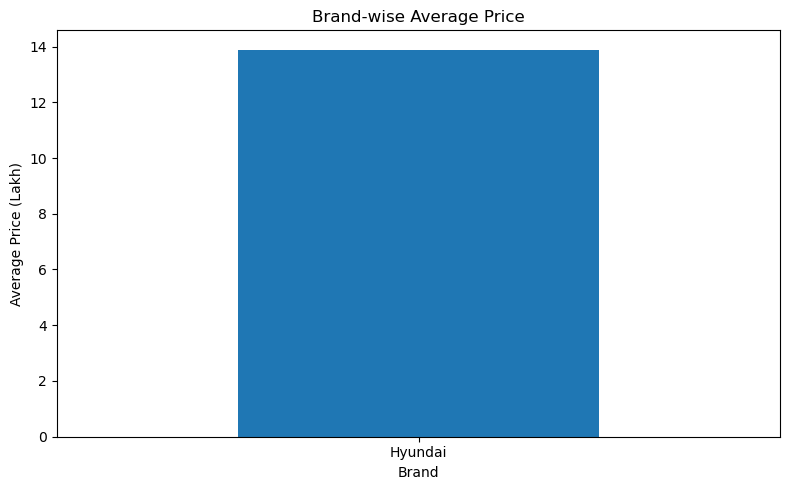

In [298]:
import matplotlib.pyplot as plt

brand_avg_price = (
    df.groupby("Brand")["Price"]
    .mean()
)

plt.figure(figsize=(8, 5))

brand_avg_price.plot(kind="bar")

plt.title("Brand-wise Average Price")
plt.xlabel("Brand")
plt.ylabel("Average Price (Lakh)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

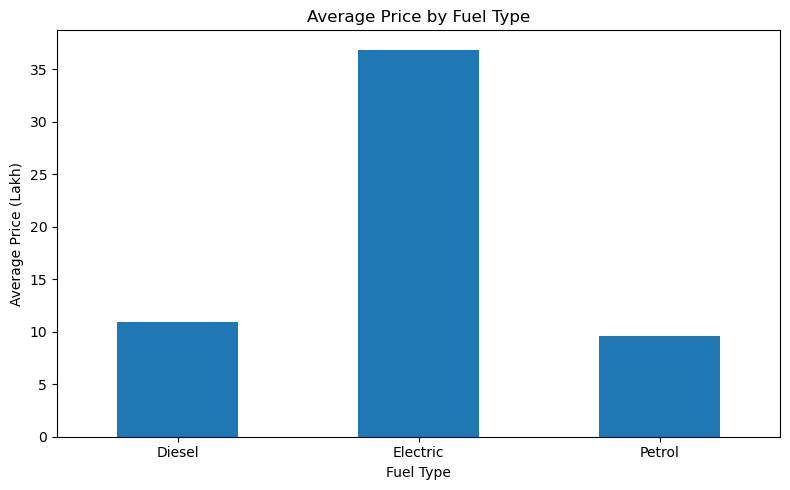

In [299]:
fuel_avg_price = (
    df.groupby("Fuel Type")["Price"]
    .mean()
    .dropna()
)

plt.figure(figsize=(8, 5))

fuel_avg_price.plot(kind="bar")

plt.title("Average Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price (Lakh)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [300]:
transmission_count = (
    df["Transmission_Type"]
    .dropna()
    .value_counts()
)

print(transmission_count)

Transmission_Type
Manual & Automatic    11
Automatic              2
Name: count, dtype: int64


Dataset loaded successfully!
Shape: (56, 9)

Correlation Matrix:
                 Price  Engine_cc  Mileage_kmpl   Seating    Rating
Price         1.000000   0.577210     -0.465855  0.014052 -0.816094
Engine_cc     0.577210   1.000000      0.503094  0.378736 -0.248925
Mileage_kmpl -0.465855   0.503094      1.000000       NaN -0.780948
Seating       0.014052   0.378736           NaN  1.000000  0.134858
Rating       -0.816094  -0.248925     -0.780948  0.134858  1.000000


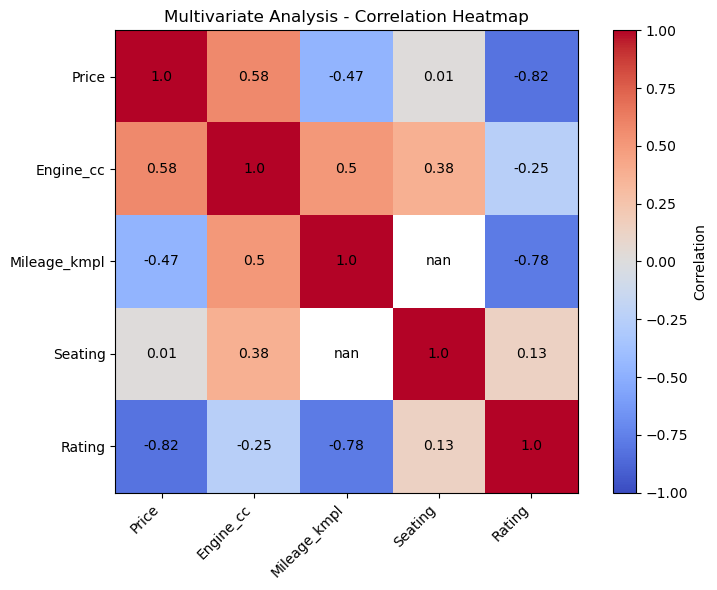

In [2]:
# ==========================================
# LOAD CLEANED DATA
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("hyundai_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)


# ==========================================
# SELECT NUMERICAL COLUMNS
# ==========================================

numeric_data = df[
    [
        "Price",
        "Engine_cc",
        "Mileage_kmpl",
        "Seating",
        "Rating"
    ]
]


# ==========================================
# CORRELATION MATRIX
# ==========================================

correlation = numeric_data.corr()

print("\nCorrelation Matrix:")
print(correlation)


# ==========================================
# CORRELATION HEATMAP
# ==========================================

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

# Display values inside heatmap
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):

        plt.text(
            j,
            i,
            round(correlation.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Multivariate Analysis - Correlation Heatmap")

plt.tight_layout()
plt.show()

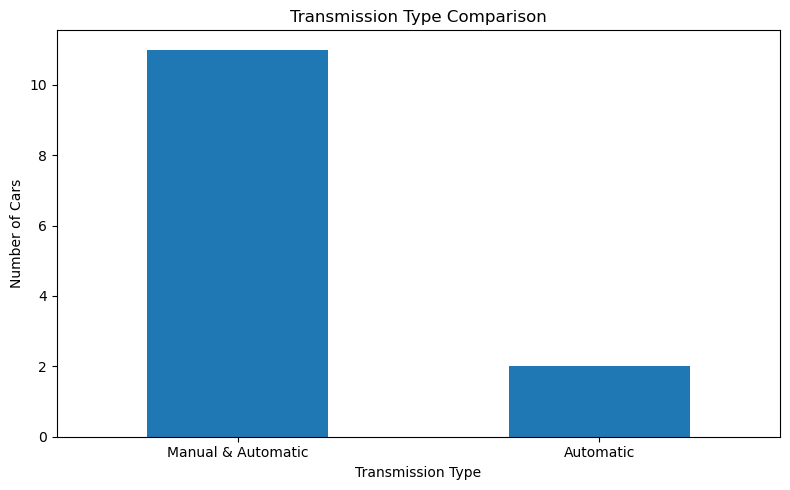

In [301]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

transmission_count.plot(kind="bar")

plt.title("Transmission Type Comparison")
plt.xlabel("Transmission Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [302]:
mileage_data = (
    df[
        df["Mileage_kmpl"].notna()
    ]
    .sort_values(
        by="Mileage_kmpl",
        ascending=False
    )
)

print(
    mileage_data[
        ["Car Name", "Mileage_kmpl"]
    ].to_string(index=False)
)

              Car Name  Mileage_kmpl
          Hyundai Aura          19.7
Hyundai Grand i10 Nios          19.0
         Hyundai Creta          18.0
           Hyundai i20          17.0
    Hyundai i20 N Line          14.6


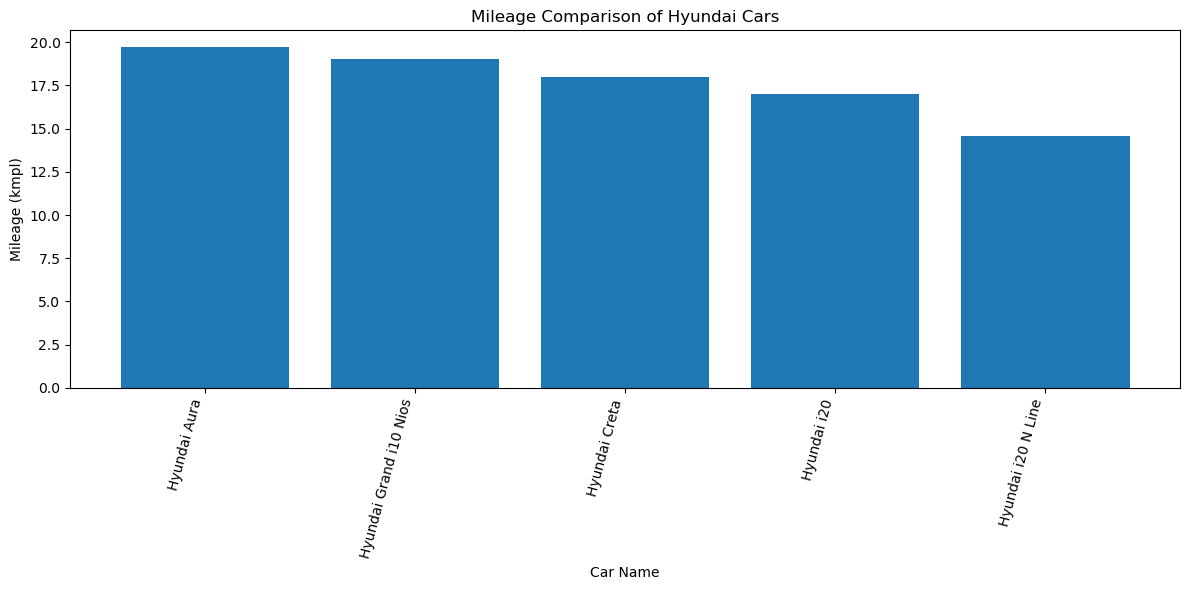

In [303]:
plt.figure(figsize=(12, 6))

plt.bar(
    mileage_data["Car Name"],
    mileage_data["Mileage_kmpl"]
)

plt.title("Mileage Comparison of Hyundai Cars")
plt.xlabel("Car Name")
plt.ylabel("Mileage (kmpl)")

plt.xticks(
    rotation=75,
    ha="right"
)

plt.tight_layout()
plt.show()

In [304]:
engine_data = (
    df[
        df["Engine_cc"].notna()
    ]
    .sort_values(
        by="Engine_cc",
        ascending=False
    )
)

print(
    engine_data[
        ["Car Name", "Engine_cc"]
    ].to_string(index=False)
)

              Car Name  Engine_cc
         Hyundai Creta     1493.0
         Hyundai Verna     1482.0
       Hyundai Alcazar     1482.0
  Hyundai Creta N Line     1482.0
           Hyundai i20     1197.0
         Hyundai Exter     1197.0
Hyundai Grand i10 Nios     1197.0
          Hyundai Aura     1197.0
         Hyundai Venue      998.0
  Hyundai Venue N Line      998.0
    Hyundai i20 N Line      998.0


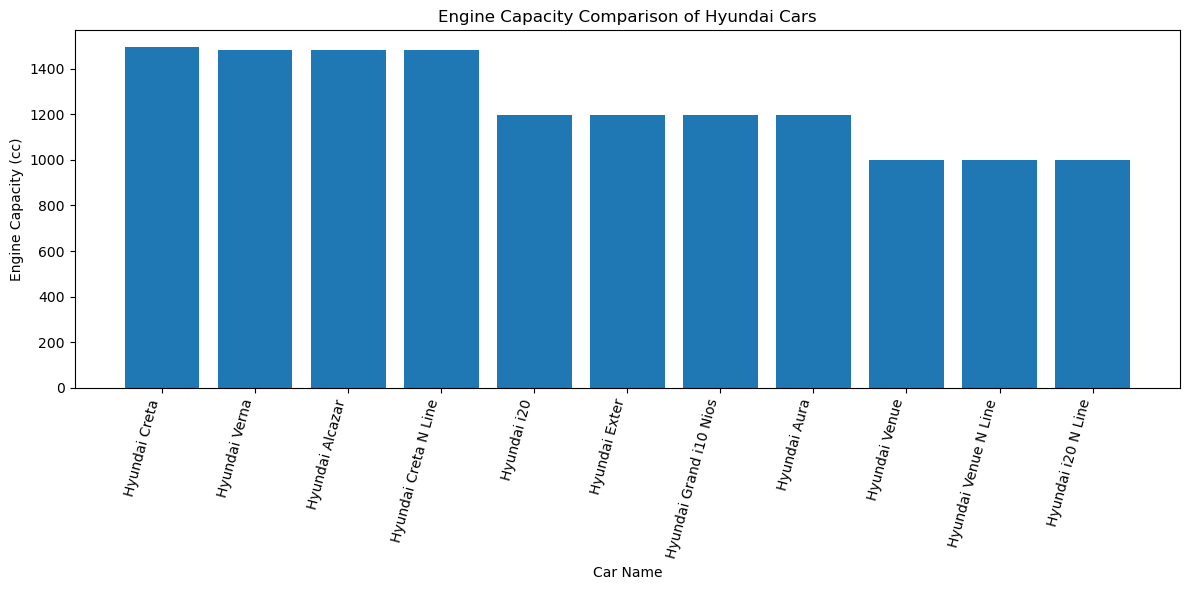

In [305]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    engine_data["Car Name"],
    engine_data["Engine_cc"]
)

plt.title("Engine Capacity Comparison of Hyundai Cars")
plt.xlabel("Car Name")
plt.ylabel("Engine Capacity (cc)")

plt.xticks(
    rotation=75,
    ha="right"
)

plt.tight_layout()
plt.show()

In [306]:
expensive_cars = (
    df[
        df["Price"].notna()
    ]
    .sort_values(
        by="Price",
        ascending=False
    )
    .head(10)
)

print(
    expensive_cars[
        ["Car Name", "Price"]
    ].to_string(index=False)
)

              Car Name  Price
       Hyundai Ioniq 5  55.71
  Hyundai Creta N Line  19.03
Hyundai Creta Electric  18.03
       Hyundai Alcazar  14.51
         Hyundai Verna  10.99
         Hyundai Creta  10.91
  Hyundai Venue N Line  10.66
    Hyundai i20 N Line   9.27
         Hyundai Venue   8.00
           Hyundai i20   6.00


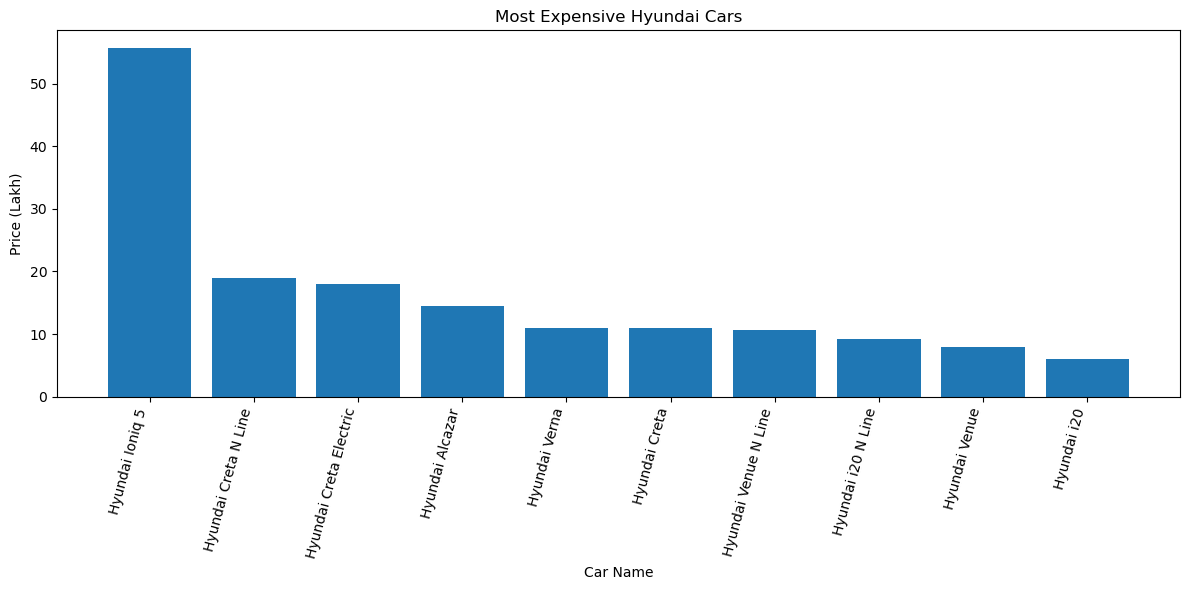

In [307]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    expensive_cars["Car Name"],
    expensive_cars["Price"]
)

plt.title("Most Expensive Hyundai Cars")
plt.xlabel("Car Name")
plt.ylabel("Price (Lakh)")

plt.xticks(
    rotation=75,
    ha="right"
)

plt.tight_layout()
plt.show()

In [308]:
cheapest_cars = (
    df[
        df["Price"].notna()
    ]
    .sort_values(
        by="Price",
        ascending=True
    )
    .head(10)
)

print(
    cheapest_cars[
        ["Car Name", "Price"]
    ].to_string(index=False)
)

              Car Name  Price
Hyundai Grand i10 Nios   5.60
         Hyundai Exter   5.81
           Hyundai i20   6.00
          Hyundai Aura   6.00
         Hyundai Venue   8.00
    Hyundai i20 N Line   9.27
  Hyundai Venue N Line  10.66
         Hyundai Creta  10.91
         Hyundai Verna  10.99
       Hyundai Alcazar  14.51


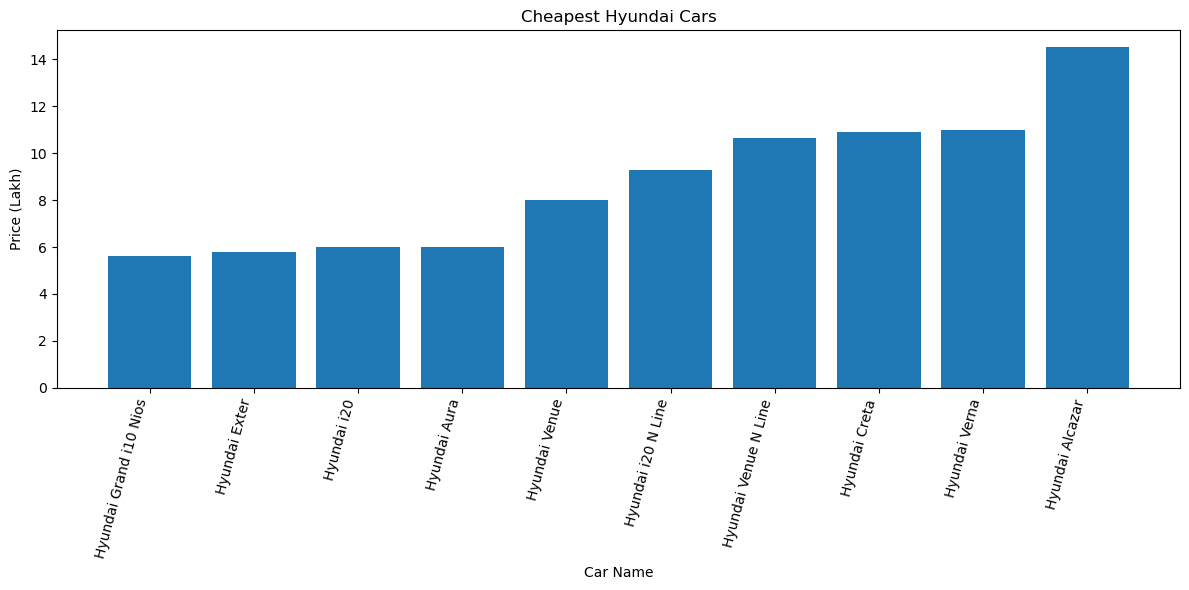

In [309]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    cheapest_cars["Car Name"],
    cheapest_cars["Price"]
)

plt.title("Cheapest Hyundai Cars")
plt.xlabel("Car Name")
plt.ylabel("Price (Lakh)")

plt.xticks(
    rotation=75,
    ha="right"
)

plt.tight_layout()
plt.show()

In [310]:
rating_data = (
    df[
        df["Rating"].notna()
    ]
    .sort_values(
        by="Rating",
        ascending=False
    )
)

print(
    rating_data[
        ["Car Name", "Rating"]
    ].to_string(index=False)
)

                      Car Name  Rating
                 Hyundai Verna     4.8
          Hyundai Venue N Line     4.8
     2023 Hyundai Venue N Line     4.8
            2023 Hyundai Exter     4.7
            2023 Hyundai Creta     4.7
        Hyundai Creta Electric     4.7
            Hyundai i20 N Line     4.7
                 Hyundai Venue     4.7
            2023 Hyundai Verna     4.7
                 Hyundai Creta     4.6
          2023 Hyundai Alcazar     4.6
             2020 Hyundai Aura     4.6
         2014 Hyundai Santa Fe     4.6
               Hyundai Elantra     4.6
          2023 Hyundai Ioniq 5     4.6
            2023 Hyundai Venue     4.6
               Hyundai Alcazar     4.6
                   Hyundai i20     4.6
                 Hyundai Exter     4.6
                  Hyundai Aura     4.6
          Hyundai Creta N Line     4.6
   2019 Hyundai Grand i10 Nios     4.5
        Hyundai Grand i10 Nios     4.5
            Hyundai i20 Active     4.5
             Hyundai Gran

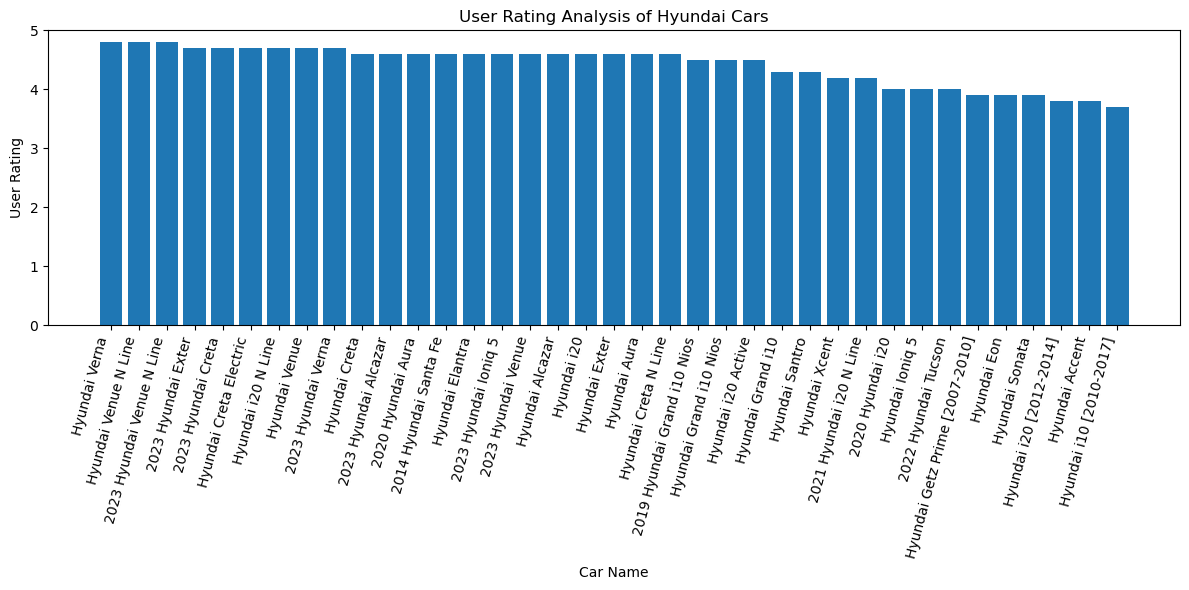

In [311]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    rating_data["Car Name"],
    rating_data["Rating"]
)

plt.title("User Rating Analysis of Hyundai Cars")
plt.xlabel("Car Name")
plt.ylabel("User Rating")

plt.xticks(
    rotation=75,
    ha="right"
)

plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [312]:
category_count = (
    df[
        df["Price_Category"] != "Not Available"
    ]["Price_Category"]
    .value_counts()
)

print(category_count)

Price_Category
Mid-range    6
Budget       6
Premium      1
Name: count, dtype: int64


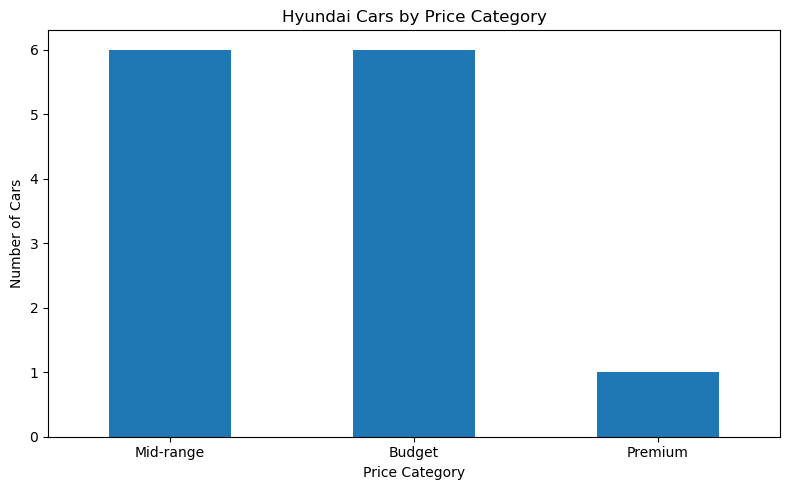

In [313]:
plt.figure(figsize=(8, 5))

category_count.plot(kind="bar")

plt.title("Hyundai Cars by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Cars")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [314]:
fuel_count = df["Fuel Type"].dropna().value_counts()

print(fuel_count)

Fuel Type
Petrol      10
Electric     2
Diesel       1
Name: count, dtype: int64


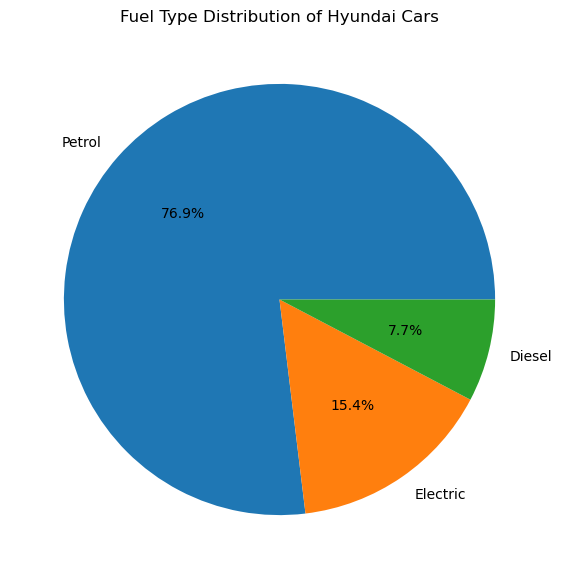

In [315]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.pie(
    fuel_count,
    labels=fuel_count.index,
    autopct="%1.1f%%"
)

plt.title("Fuel Type Distribution of Hyundai Cars")

plt.show()

In [316]:
transmission_count = (
    df["Transmission_Type"]
    .dropna()
    .value_counts()
)

print(transmission_count)

Transmission_Type
Manual & Automatic    11
Automatic              2
Name: count, dtype: int64


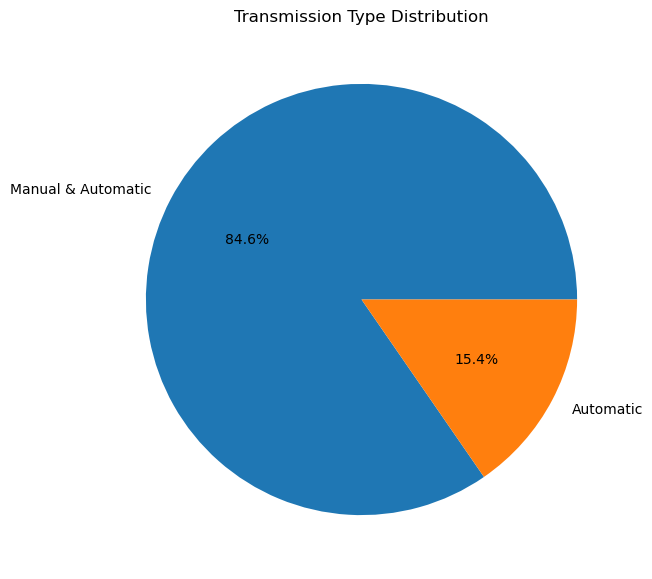

In [317]:
plt.figure(figsize=(7, 7))

plt.pie(
    transmission_count,
    labels=transmission_count.index,
    autopct="%1.1f%%"
)

plt.title("Transmission Type Distribution")

plt.show()

In [318]:
scatter_data = df[
    df["Price"].notna() &
    df["Mileage_kmpl"].notna()
]

print(
    scatter_data[
        ["Car Name", "Price", "Mileage_kmpl"]
    ]
)

                  Car Name  Price  Mileage_kmpl
0            Hyundai Creta  10.91          18.0
2              Hyundai i20   6.00          17.0
4   Hyundai Grand i10 Nios   5.60          19.0
6             Hyundai Aura   6.00          19.7
10      Hyundai i20 N Line   9.27          14.6


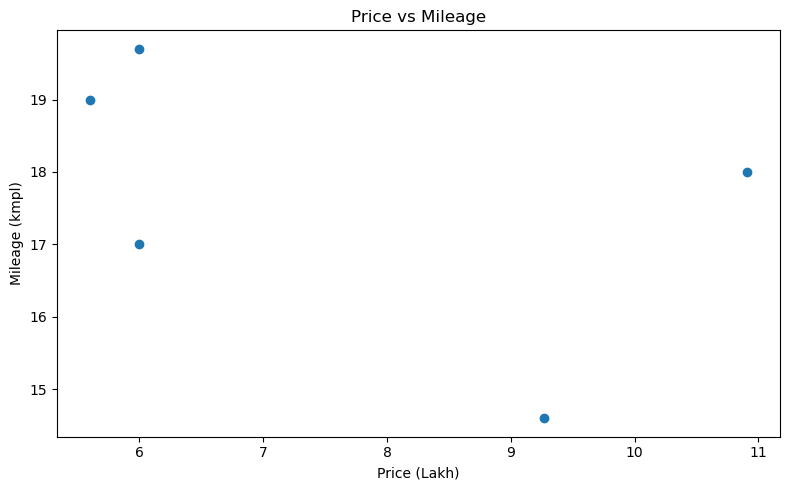

In [319]:
plt.figure(figsize=(8, 5))

plt.scatter(
    scatter_data["Price"],
    scatter_data["Mileage_kmpl"]
)

plt.title("Price vs Mileage")
plt.xlabel("Price (Lakh)")
plt.ylabel("Mileage (kmpl)")

plt.tight_layout()
plt.show()

              Car Name  Price  Rating
         Hyundai Creta  10.91     4.6
         Hyundai Venue   8.00     4.7
           Hyundai i20   6.00     4.6
         Hyundai Exter   5.81     4.6
Hyundai Grand i10 Nios   5.60     4.5
         Hyundai Verna  10.99     4.8
          Hyundai Aura   6.00     4.6
       Hyundai Alcazar  14.51     4.6
Hyundai Creta Electric  18.03     4.7
  Hyundai Venue N Line  10.66     4.8
    Hyundai i20 N Line   9.27     4.7
  Hyundai Creta N Line  19.03     4.6
       Hyundai Ioniq 5  55.71     4.0


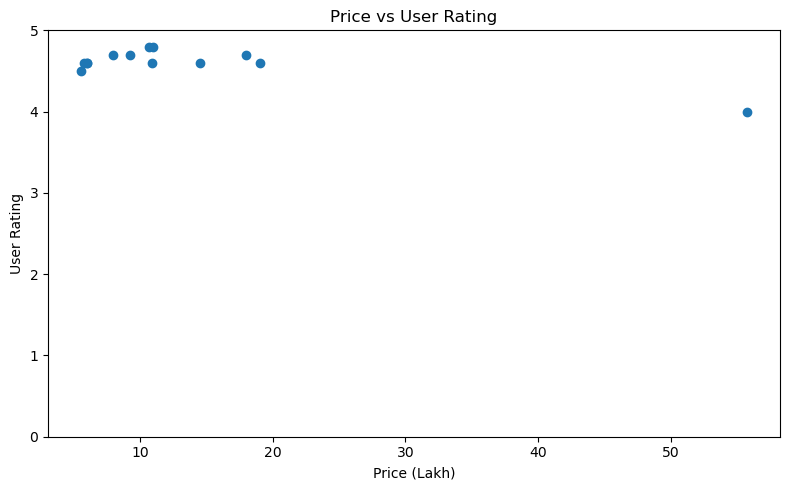

In [321]:
# ==========================================
# PRICE VS USER RATING
# ==========================================

rating_price_data = df[
    df["Price"].notna() &
    df["Rating"].notna()
]

print(
    rating_price_data[
        ["Car Name", "Price", "Rating"]
    ].to_string(index=False)
)


# Create scatter plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    rating_price_data["Price"],
    rating_price_data["Rating"]
)

plt.title("Price vs User Rating")
plt.xlabel("Price (Lakh)")
plt.ylabel("User Rating")

plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [322]:
print("========== FINAL PROJECT SUMMARY ==========")

print(
    "Total records scraped:",
    len(df)
)

print(
    "Cars with available price:",
    df["Price"].notna().sum()
)

print(
    "Average Price:",
    round(df["Price"].mean(), 2),
    "Lakh"
)

print(
    "Average Mileage:",
    round(df["Mileage_kmpl"].mean(), 2),
    "kmpl"
)

print(
    "Average Engine Capacity:",
    round(df["Engine_cc"].mean(), 2),
    "cc"
)

print(
    "Average User Rating:",
    round(df["Rating"].mean(), 2)
)

print("\nFuel Type Distribution:")
print(df["Fuel Type"].value_counts())

print("\nTransmission Distribution:")
print(df["Transmission_Type"].value_counts())

print("\nPrice Category Distribution:")
print(
    df[
        df["Price_Category"] != "Not Available"
    ]["Price_Category"].value_counts()
)

========== FINAL PROJECT SUMMARY ==========
Total records scraped: 56
Cars with available price: 13
Average Price: 13.89 Lakh
Average Mileage: 17.66 kmpl
Average Engine Capacity: 1247.36 cc
Average User Rating: 4.41

Fuel Type Distribution:
Fuel Type
Petrol      10
Electric     2
Diesel       1
Name: count, dtype: int64

Transmission Distribution:
Transmission_Type
Manual & Automatic    11
Automatic              2
Name: count, dtype: int64

Price Category Distribution:
Price_Category
Mid-range    6
Budget       6
Premium      1
Name: count, dtype: int64


In [323]:
highest_rated_car = (
    df[
        df["Rating"].notna()
    ]
    .sort_values(
        by="Rating",
        ascending=False
    )
    .iloc[0]
)

print("Highest available rating:")
print(highest_rated_car[
    ["Car Name", "Rating"]
])

Highest available rating:
Car Name    Hyundai Verna
Rating                4.8
Name: 5, dtype: object


In [324]:
highest_price_car = (
    df[
        df["Price"].notna()
    ]
    .sort_values(
        by="Price",
        ascending=False
    )
    .iloc[0]
)

print("Highest available price:")
print(highest_price_car[
    ["Car Name", "Price"]
])

Highest available price:
Car Name    Hyundai Ioniq 5
Price                 55.71
Name: 12, dtype: object


In [325]:
highest_mileage_car = (
    df[
        df["Mileage_kmpl"].notna()
    ]
    .sort_values(
        by="Mileage_kmpl",
        ascending=False
    )
    .iloc[0]
)

print("Highest available mileage:")
print(highest_mileage_car[
    ["Car Name", "Mileage_kmpl"]
])

Highest available mileage:
Car Name        Hyundai Aura
Mileage_kmpl            19.7
Name: 6, dtype: object


In [326]:
largest_engine_car = (
    df[
        df["Engine_cc"].notna()
    ]
    .sort_values(
        by="Engine_cc",
        ascending=False
    )
    .iloc[0]
)

print("Largest available engine:")
print(largest_engine_car[
    ["Car Name", "Engine_cc"]
])

Largest available engine:
Car Name     Hyundai Creta
Engine_cc           1493.0
Name: 0, dtype: object


In [327]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

In [328]:
# ==========================================
# SAVE ALL GRAPHS IN ONE PDF
# ==========================================

from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt


with PdfPages("hyundai_all_graphs.pdf") as pdf:

    # ======================================
    # 1. Brand-wise Average Price
    # ======================================

    brand_avg_price = (
        df.groupby("Brand")["Price"]
        .mean()
    )

    plt.figure(figsize=(8, 5))
    brand_avg_price.plot(kind="bar")

    plt.title("Brand-wise Average Price")
    plt.xlabel("Brand")
    plt.ylabel("Average Price (Lakh)")
    plt.xticks(rotation=0)

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 2. Average Price by Fuel Type
    # ======================================

    fuel_avg_price = (
        df.groupby("Fuel Type")["Price"]
        .mean()
        .dropna()
    )

    plt.figure(figsize=(8, 5))
    fuel_avg_price.plot(kind="bar")

    plt.title("Average Price by Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Average Price (Lakh)")
    plt.xticks(rotation=0)

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 3. Transmission Comparison
    # ======================================

    transmission_count = (
        df["Transmission_Type"]
        .dropna()
        .value_counts()
    )

    plt.figure(figsize=(8, 5))
    transmission_count.plot(kind="bar")

    plt.title("Transmission Type Comparison")
    plt.xlabel("Transmission Type")
    plt.ylabel("Number of Cars")
    plt.xticks(rotation=0)

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 4. Mileage Comparison
    # ======================================

    mileage_data = (
        df[df["Mileage_kmpl"].notna()]
        .sort_values(
            by="Mileage_kmpl",
            ascending=False
        )
    )

    plt.figure(figsize=(12, 6))

    plt.bar(
        mileage_data["Car Name"],
        mileage_data["Mileage_kmpl"]
    )

    plt.title("Mileage Comparison of Hyundai Cars")
    plt.xlabel("Car Name")
    plt.ylabel("Mileage (kmpl)")

    plt.xticks(
        rotation=75,
        ha="right"
    )

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 5. Engine Comparison
    # ======================================

    engine_data = (
        df[df["Engine_cc"].notna()]
        .sort_values(
            by="Engine_cc",
            ascending=False
        )
    )

    plt.figure(figsize=(12, 6))

    plt.bar(
        engine_data["Car Name"],
        engine_data["Engine_cc"]
    )

    plt.title("Engine Capacity Comparison")
    plt.xlabel("Car Name")
    plt.ylabel("Engine Capacity (cc)")

    plt.xticks(
        rotation=75,
        ha="right"
    )

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 6. Most Expensive Cars
    # ======================================

    expensive_cars = (
        df[df["Price"].notna()]
        .sort_values(
            by="Price",
            ascending=False
        )
        .head(10)
    )

    plt.figure(figsize=(12, 6))

    plt.bar(
        expensive_cars["Car Name"],
        expensive_cars["Price"]
    )

    plt.title("Most Expensive Hyundai Cars")
    plt.xlabel("Car Name")
    plt.ylabel("Price (Lakh)")

    plt.xticks(
        rotation=75,
        ha="right"
    )

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 7. Cheapest Cars
    # ======================================

    cheapest_cars = (
        df[df["Price"].notna()]
        .sort_values(
            by="Price",
            ascending=True
        )
        .head(10)
    )

    plt.figure(figsize=(12, 6))

    plt.bar(
        cheapest_cars["Car Name"],
        cheapest_cars["Price"]
    )

    plt.title("Cheapest Hyundai Cars")
    plt.xlabel("Car Name")
    plt.ylabel("Price (Lakh)")

    plt.xticks(
        rotation=75,
        ha="right"
    )

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 8. User Rating Analysis
    # ======================================

    rating_data = (
        df[df["Rating"].notna()]
        .sort_values(
            by="Rating",
            ascending=False
        )
    )

    plt.figure(figsize=(12, 6))

    plt.bar(
        rating_data["Car Name"],
        rating_data["Rating"]
    )

    plt.title("User Rating Analysis")
    plt.xlabel("Car Name")
    plt.ylabel("User Rating")

    plt.xticks(
        rotation=75,
        ha="right"
    )

    plt.ylim(0, 5)

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 9. Budget / Mid-range / Premium
    # ======================================

    category_count = (
        df[
            df["Price_Category"] != "Not Available"
        ]["Price_Category"]
        .value_counts()
    )

    plt.figure(figsize=(8, 5))

    category_count.plot(kind="bar")

    plt.title("Hyundai Cars by Price Category")
    plt.xlabel("Price Category")
    plt.ylabel("Number of Cars")

    plt.xticks(rotation=0)

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 10. Fuel Type Pie Chart
    # ======================================

    fuel_count = (
        df["Fuel Type"]
        .dropna()
        .value_counts()
    )

    plt.figure(figsize=(7, 7))

    plt.pie(
        fuel_count,
        labels=fuel_count.index,
        autopct="%1.1f%%"
    )

    plt.title("Fuel Type Distribution")

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 11. Transmission Pie Chart
    # ======================================

    transmission_count = (
        df["Transmission_Type"]
        .dropna()
        .value_counts()
    )

    plt.figure(figsize=(7, 7))

    plt.pie(
        transmission_count,
        labels=transmission_count.index,
        autopct="%1.1f%%"
    )

    plt.title("Transmission Type Distribution")

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 12. Price vs Mileage
    # ======================================

    scatter_data = df[
        df["Price"].notna()
        &
        df["Mileage_kmpl"].notna()
    ]

    plt.figure(figsize=(8, 5))

    plt.scatter(
        scatter_data["Price"],
        scatter_data["Mileage_kmpl"]
    )

    plt.title("Price vs Mileage")
    plt.xlabel("Price (Lakh)")
    plt.ylabel("Mileage (kmpl)")

    plt.tight_layout()
    pdf.savefig()
    plt.close()


    # ======================================
    # 13. Price vs User Rating
    # ======================================

    rating_price_data = df[
        df["Price"].notna()
        &
        df["Rating"].notna()
    ]

    plt.figure(figsize=(8, 5))

    plt.scatter(
        rating_price_data["Price"],
        rating_price_data["Rating"]
    )

    plt.title("Price vs User Rating")
    plt.xlabel("Price (Lakh)")
    plt.ylabel("User Rating")

    plt.ylim(0, 5)

    plt.tight_layout()
    pdf.savefig()
    plt.close()


print("All 13 graphs saved successfully!")
print("File name: hyundai_all_graphs.pdf")

All 13 graphs saved successfully!
File name: hyundai_all_graphs.pdf
